# Portfolio Optimization on the Euro Stoxx 50 – Asset Management Take-Home
**LIUC – MSc in Economics, Banking and Finance (Asset Management course)**

Group assignment. Opportunity set, Single Index Model, Vasicek-adjusted betas, constrained optimization (Sharpe, GMV, Kataoka safety-first, Elton–Gruber–Padberg cutoff rate C*) and an interactive backtest.

> The dataset is **not included** (see `data/README.md`). Outputs stored in this notebook come from the original run; use `make_sample_data.py` to generate a synthetic file and re-run end to end.


In [1]:
# !pip install pandas numpy scipy matplotlib seaborn openpyxl

# Importazione librerie
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.optimize as sco
from scipy import stats
from scipy.stats import jarque_bera

plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')

# Fattore di annualizzazione: dati mensili -> x12 per rendimenti, x sqrt(12) per volatilità
FREQ = 12

print('Librerie caricate.')


Librerie caricate.


---
## SEZIONE 1 – Costruzione dell'Opportunity Set
Caricamento dati, calcolo log-rendimenti, statistiche descrittive, test di normalità e analisi delle correlazioni tra asset.


### 1.1 – Caricamento e pulizia dati
Lettura del file Excel, normalizzazione dei nomi colonna e impostazione dell'indice temporale.


In [2]:
# Lettura del file Excel con prezzi mensili
df_raw = pd.read_excel('../data/DATABASE.xlsx', header=0)

# Uniforma nomi colonne in minuscolo; imposta la data come indice
newcols = ['date'] + [c.lower() for c in df_raw.columns[1:]]
df_raw.columns = newcols
df_raw['date'] = pd.to_datetime(df_raw['date'])
df_raw.set_index('date', inplace=True)

# Forza la conversione numerica; eventuali valori non parsabili diventano NaN
df_raw = df_raw.apply(pd.to_numeric, errors='coerce')

print(f'Dataset: {df_raw.shape[0]} osservazioni, {df_raw.shape[1]} serie')
print(f'Periodo: {df_raw.index.min().strftime("%Y-%m")} → {df_raw.index.max().strftime("%Y-%m")}')
df_raw.head(5)


Dataset: 120 osservazioni, 27 serie
Periodo: 2016-04 → 2026-03


,asml,mc,sap,or,tte,sie,rms,air,alv,san,...,muv2,isp,eni,enel,race,bmw,bas,una,bund10y,sx5e_price
date,,,,,,,,,,,,,,,,,,,,,
2016-04-29,84.40,145.10,68.32,158.45,43.930,82.476,311.00,54.61,148.25,71.7192,...,161.95,2.420,14.20,3.958,39.32,80.50,72.15,41.347,0.271,3037.62
2016-05-31,89.40,144.05,72.96,168.90,43.675,87.608,324.95,56.02,146.70,73.2906,...,168.85,2.308,13.73,4.074,38.10,75.89,69.43,43.610,0.138,3061.44
2016-06-30,88.39,136.00,67.16,172.00,43.380,83.100,336.95,51.73,127.80,74.5139,...,150.25,1.702,14.52,3.980,36.65,65.79,68.64,44.473,-0.131,2874.15
2016-07-29,98.94,153.40,78.41,170.25,42.760,87.907,384.80,52.63,128.30,75.7373,...,149.20,1.970,13.68,4.118,40.44,77.05,70.26,44.934,-0.121,3001.36
2016-08-31,95.37,151.70,78.76,169.35,42.750,96.894,378.60,52.29,133.55,68.6956,...,162.05,2.130,13.54,3.958,43.20,78.01,72.90,44.216,-0.066,3027.86


### 1.2 – Separazione asset / mercato / risk-free
Distinzione tra asset rischiosi, benchmark di mercato (SX5E) e tasso privo di rischio (Bund 10Y).


In [3]:
# Colonne macro escluse dall'universo investibile
MACRO_COLS = ['bund10y', 'sx5e_price']
ASSET_COLS = [c for c in df_raw.columns if c not in MACRO_COLS]

df_assets = df_raw[ASSET_COLS].copy()
df_market = df_raw['sx5e_price'].copy()            # benchmark: EuroStoxx 50

# Tasso privo di rischio: ultimo yield del Bund 10Y osservato nel dataset
rf_annuo = df_raw['bund10y'].iloc[-1] / 100

print(f'Asset rischiosi : {len(ASSET_COLS)}')
print(f'Lista           : {ASSET_COLS}')
print(f'Risk-Free (ann.): {rf_annuo:.4f} ({rf_annuo:.2%})')


Asset rischiosi : 25
Lista           : ['asml', 'mc', 'sap', 'or', 'tte', 'sie', 'rms', 'air', 'alv', 'san', 'su', 'ai', 'itx', 'dte', 'ibe', 'bnp', 'mbg', 'muv2', 'isp', 'eni', 'enel', 'race', 'bmw', 'bas', 'una']
Risk-Free (ann.): 0.0300 (3.00%)


### 1.3 – Log-rendimenti mensili
Calcolo dei log-rendimenti come differenza dei logaritmi dei prezzi; allineamento temporale tra asset e mercato.


In [4]:
# Log-rendimenti: ln(P_t / P_{t-1}), eliminazione prima riga (NaN) e osservazioni mancanti
log_ret        = np.log(df_assets / df_assets.shift(1)).iloc[1:].dropna()
log_ret_market = np.log(df_market / df_market.shift(1)).iloc[1:].dropna()

# Allineamento: mantiene solo i mesi presenti in entrambe le serie
common_idx     = log_ret.index.intersection(log_ret_market.index)
log_ret        = log_ret.loc[common_idx]
log_ret_market = log_ret_market.loc[common_idx]

n_assets = len(log_ret.columns)
n_obs    = len(log_ret)

print(f'Osservazioni (mesi) : {n_obs}')
print(f'Periodo rendimenti  : {log_ret.index.min().strftime("%Y-%m")} → {log_ret.index.max().strftime("%Y-%m")}')
log_ret.head()


Osservazioni (mesi) : 119
Periodo rendimenti  : 2016-05 → 2026-03


,asml,mc,sap,or,tte,sie,rms,air,alv,san,...,bnp,mbg,muv2,isp,eni,enel,race,bmw,bas,una
date,,,,,,,,,,,,,,,,,,,,,
2016-05-31,0.057553,-0.007263,0.065709,0.063868,-0.005822,0.060365,0.043878,0.025492,-0.010510,0.021674,...,0.073467,0.011476,0.041723,-0.047386,-0.033659,0.028886,-0.031519,-0.058972,-0.038428,0.053287
2016-06-30,-0.011362,-0.057506,-0.082834,0.018188,-0.006777,-0.052828,0.036263,-0.079671,-0.137923,0.016553,...,-0.224576,-0.137203,-0.116710,-0.304577,0.055944,-0.023343,-0.038801,-0.142817,-0.011444,0.019596
2016-07-29,0.112755,0.120394,0.154874,-0.010227,-0.014395,0.056235,0.132789,0.017248,0.003905,0.016285,...,0.109490,0.127865,-0.007013,0.146230,-0.059592,0.034086,0.098406,0.157987,0.023327,0.010312
2016-08-31,-0.036750,-0.011144,0.004454,-0.005300,-0.000234,0.097338,-0.016243,-0.006481,0.040105,-0.097586,...,0.027792,0.020511,0.082617,0.078088,-0.010287,-0.039629,0.066021,0.012382,0.036886,-0.016108
2016-09-30,0.024035,0.000659,0.027056,-0.007409,-0.013660,-0.026977,-0.044146,0.029212,-0.010917,-0.020920,...,0.003611,0.010100,0.024083,-0.076060,-0.054642,0.002523,0.067788,-0.041885,0.043091,-0.002196


### 1.4 – Statistiche descrittive annualizzate
Rendimento atteso, volatilità, Sharpe grezzo, skewness e curtosi per ciascun asset.


In [5]:
# Annualizzazione: rendimento *12, volatilità *sqrt(12), Sharpe calcolato su base annua
stats_df = pd.DataFrame({
    'Rend_Atteso_Ann (%)' : log_ret.mean() * FREQ * 100,
    'Volatilita_Ann (%)'  : log_ret.std()  * np.sqrt(FREQ) * 100,
    'Sharpe (grezzo)'     : (log_ret.mean() * FREQ - rf_annuo) / (log_ret.std() * np.sqrt(FREQ)),
    'Skewness'            : log_ret.skew(),
    'Kurtosis (excess)'   : log_ret.kurtosis()
}).round(4)

print('=== STATISTICHE DESCRITTIVE ===')
print(stats_df.sort_values('Sharpe (grezzo)', ascending=False).to_string())


=== STATISTICHE DESCRITTIVE ===
      Rend_Atteso_Ann (%)  Volatilita_Ann (%)  Sharpe (grezzo)  Skewness  Kurtosis (excess)
asml              26.0652             29.9731           0.7695    0.0916             0.1478
race              20.1146             26.1705           0.6539    0.0886            -0.0528
rms               16.5739             25.3090           0.5362   -0.0112             1.1504
su                14.0563             22.5549           0.4901   -0.2922             0.4695
ibe               11.6743             18.6575           0.4648   -0.4146             1.1069
muv2              12.1328             20.8087           0.4388   -0.7024             1.3777
ai                10.0214             16.5684           0.4237   -0.0013             0.1982
mc                11.7027             24.6462           0.3530   -0.2348             0.3064
alv                8.9270             21.8254           0.2715   -0.0268             2.5933
or                 7.9728             18.3334   

### 1.5 – Distribuzione rendimenti e test di normalità
Test di normalità formale e visualizzazione degli istogrammi con curva normale sovrapposta.


In [6]:
# Test Jarque-Bera: H0 = distribuzione normale; p-value < 5% -> rifiuto normalità
jb_results = {}
for col in log_ret.columns:
    stat, p = jarque_bera(log_ret[col].dropna())
    jb_results[col] = {'JB stat': round(stat,2), 'p-value': round(p,4),
                       'Normale (5%)': 'Sì' if p > 0.05 else 'No'}
jb_df = pd.DataFrame(jb_results).T
print('=== TEST JARQUE-BERA ===')
print(jb_df.to_string())
print(f"\nAsset normali (p>5%): {(jb_df['Normale (5%)']=='Sì').sum()} / {n_assets}")


=== TEST JARQUE-BERA ===
     JB stat p-value Normale (5%)
asml     0.2  0.9031           Sì
mc      1.36  0.5064           Sì
sap   138.23     0.0           No
or      0.56  0.7555           Sì
tte    79.06     0.0           No
sie     8.89  0.0117           No
rms      5.5   0.064           Sì
air   943.26     0.0           No
alv    29.43     0.0           No
san     2.67  0.2636           Sì
su      2.44  0.2946           Sì
ai       0.1  0.9526           Sì
itx     3.31  0.1913           Sì
dte     16.3  0.0003           No
ibe     8.39  0.0151           No
bnp    92.22     0.0           No
mbg    17.05  0.0002           No
muv2   17.54  0.0002           No
isp    65.68     0.0           No
eni    39.83     0.0           No
enel    3.17  0.2052           Sì
race     0.2   0.904           Sì
bmw     0.92  0.6318           Sì
bas     10.2  0.0061           No
una   139.82     0.0           No

Asset normali (p>5%): 11 / 25


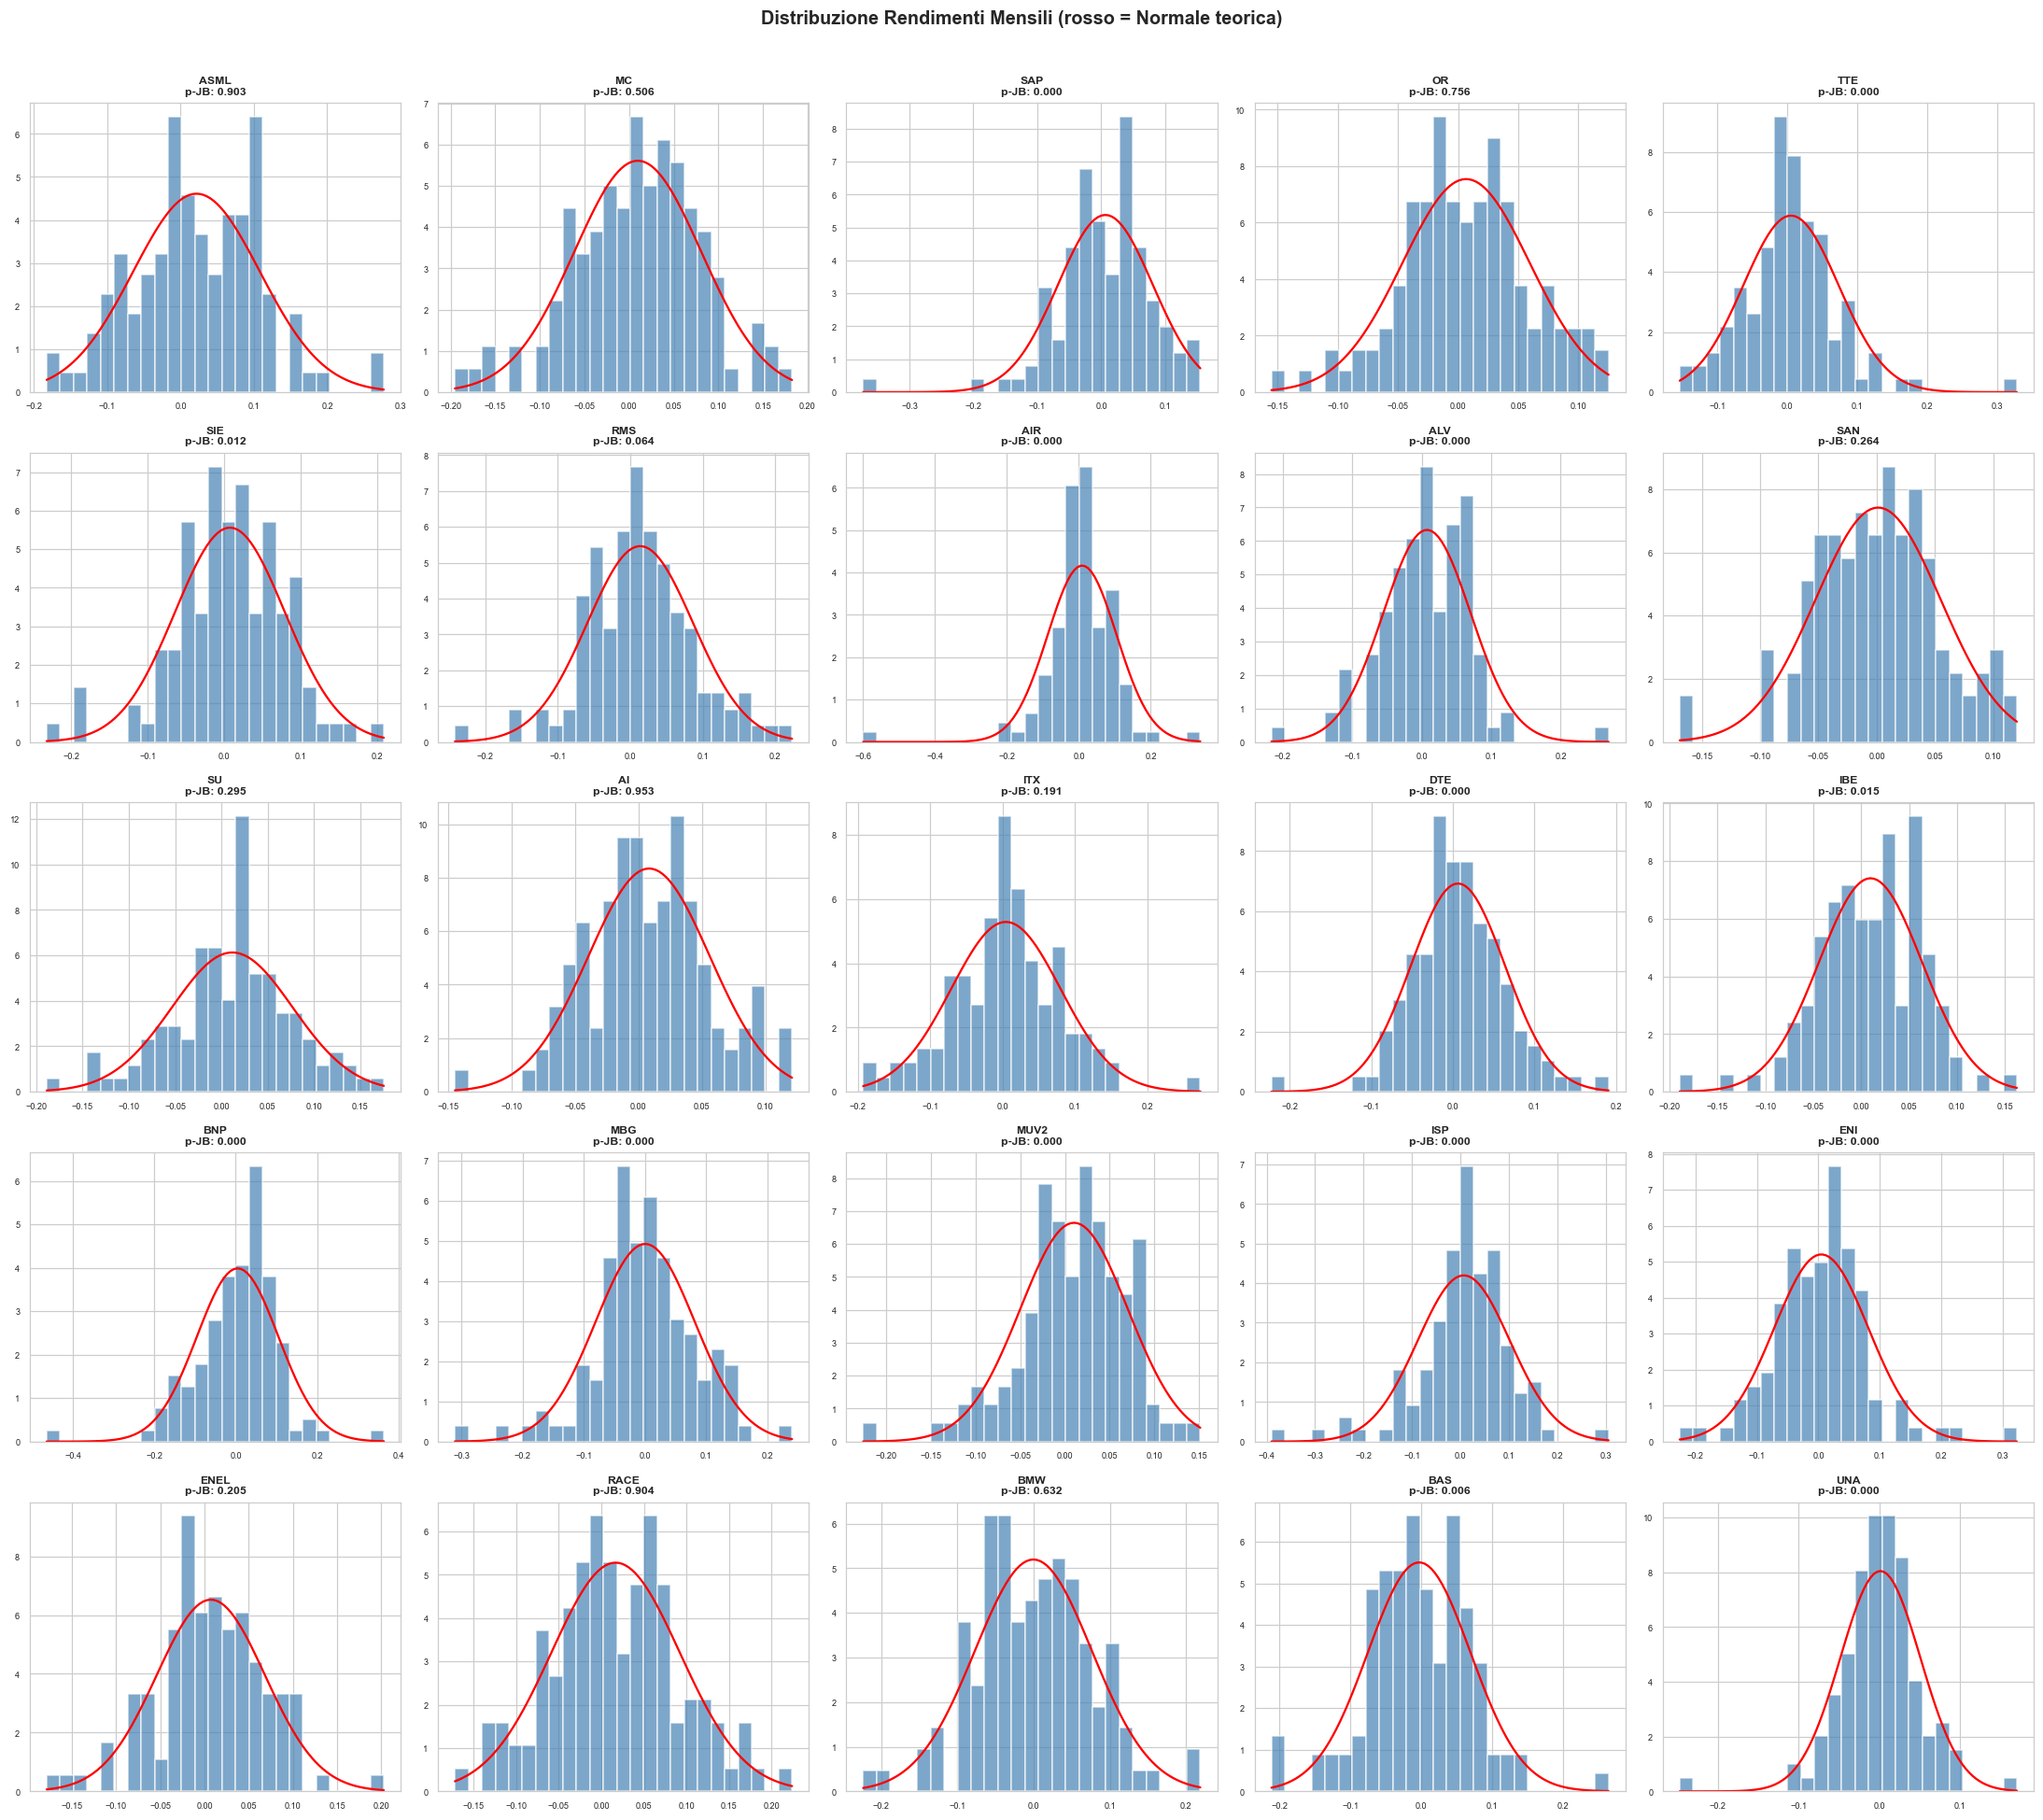

In [7]:
# Griglia di istogrammi: distribuzione empirica (barre) vs curva normale teorica (linea rossa)
ncols = 5
nrows = int(np.ceil(n_assets / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 3.5))
axes = axes.flatten()

for i, col in enumerate(log_ret.columns):
    data = log_ret[col].dropna()
    ax   = axes[i]
    ax.hist(data, bins=25, density=True, color='steelblue', edgecolor='white', alpha=0.7)
    mu_i, sig_i = data.mean(), data.std()
    x_r = np.linspace(data.min(), data.max(), 100)
    # Densità gaussiana con parametri stimati dal campione
    ax.plot(x_r, (1/(sig_i*np.sqrt(2*np.pi)))*np.exp(-0.5*((x_r-mu_i)/sig_i)**2), 'r-', lw=1.5)
    _, p_jb = jarque_bera(data)
    ax.set_title(f'{col.upper()}\np-JB: {p_jb:.3f}', fontsize=8, fontweight='bold')
    ax.tick_params(labelsize=6)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Distribuzione Rendimenti Mensili (rosso = Normale teorica)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### 1.6 – Matrice di correlazione e cluster
Heatmap delle correlazioni storiche e dendrogramma del clustering gerarchico.


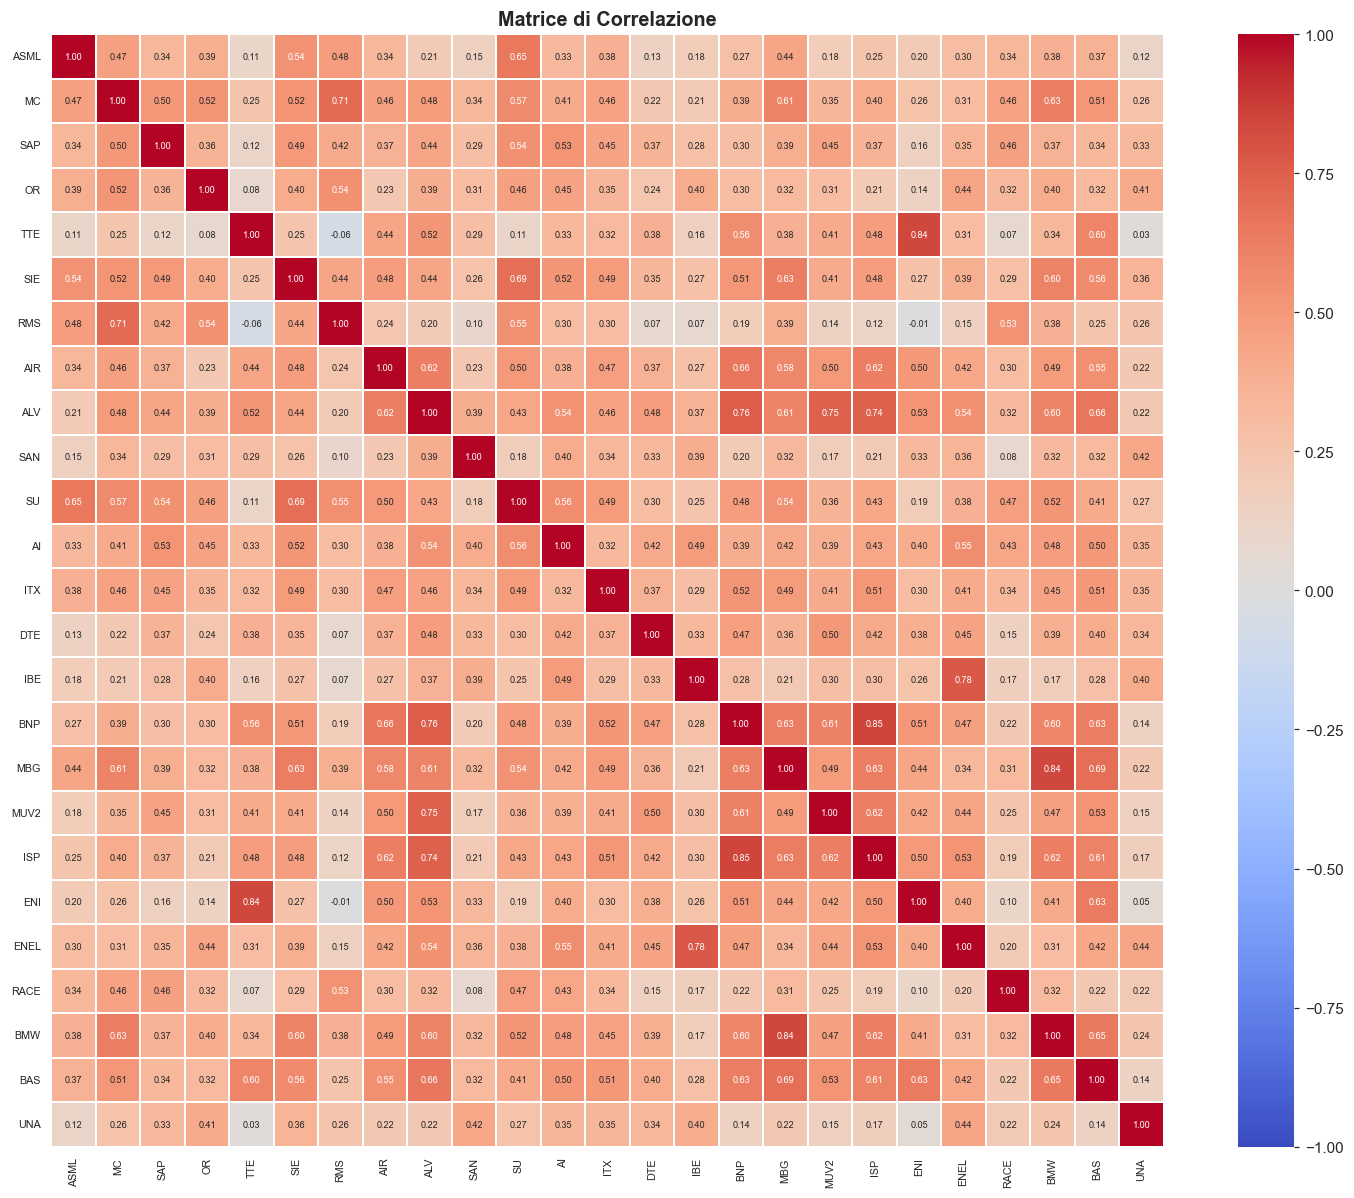

=== CORRELAZIONE MEDIA PER ASSET ===
alv     0.509
mbg     0.491
bas     0.484
bmw     0.479
bnp     0.477
isp     0.467
sie     0.466
ai      0.454
su      0.454
mc      0.452
air     0.451
itx     0.431
enel    0.428
muv2    0.424
sap     0.400
or      0.372
eni     0.370
dte     0.369
asml    0.342
tte     0.333
ibe     0.325
race    0.311
rms     0.311
san     0.310
una     0.284


In [8]:
# Matrice di correlazione dei log-rendimenti mensili
corr_matrix = log_ret.corr()

# Heatmap: scala coolwarm da -1 a +1, annotazioni con 2 decimali
fig, ax = plt.subplots(figsize=(14, 11))
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask, k=1)] = False
sns.heatmap(
    corr_matrix, ax=ax,
    cmap='coolwarm', vmin=-1, vmax=1,
    annot=True, fmt='.2f', annot_kws={'size': 6},
    linewidths=0.3, square=True,
    xticklabels=[c.upper() for c in corr_matrix.columns],
    yticklabels=[c.upper() for c in corr_matrix.index]
)
ax.set_title('Matrice di Correlazione', fontsize=13, fontweight='bold')
ax.tick_params(labelsize=7)
plt.tight_layout()
plt.show()

# Correlazione media di ogni asset con gli altri: proxy dell'esposizione sistematica
avg_corr = corr_matrix.mean().sort_values(ascending=False)
print('=== CORRELAZIONE MEDIA PER ASSET ===')
print(avg_corr.round(3).to_string())


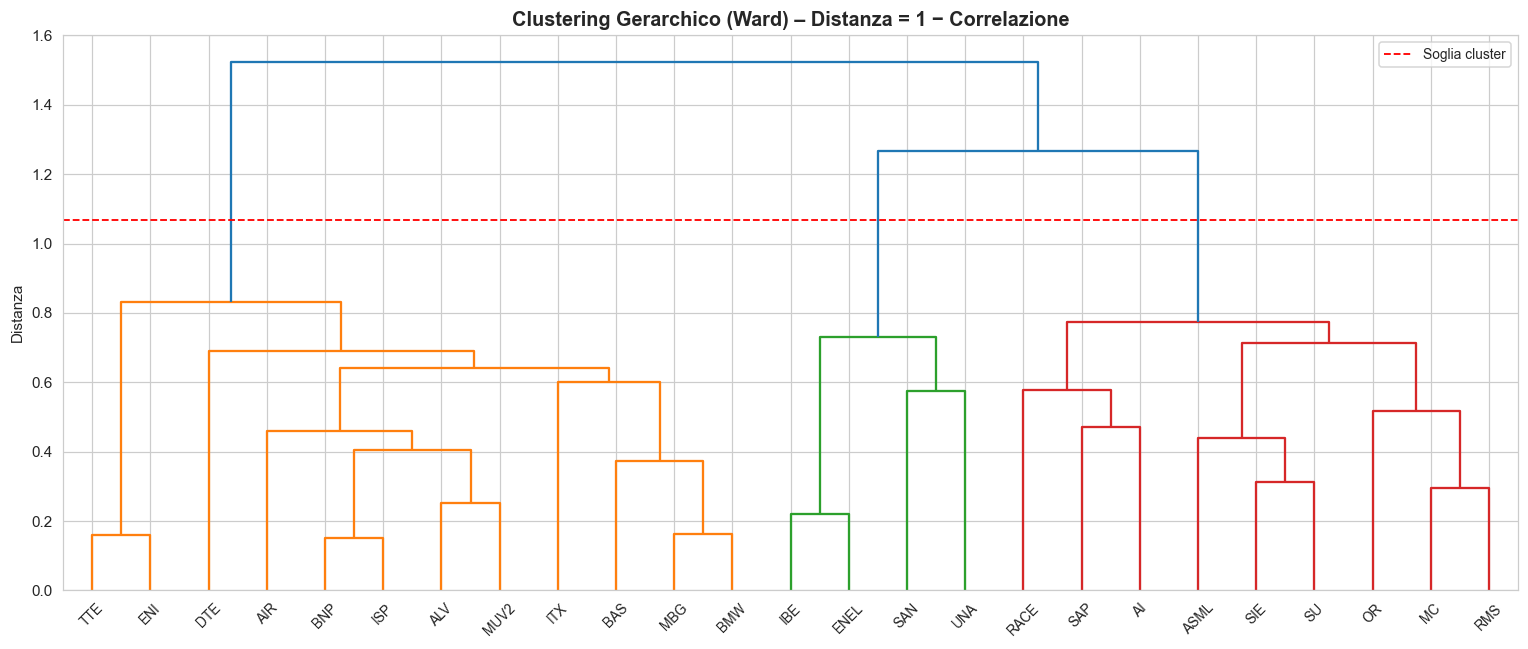

Numero di cluster identificati: 3
Asset  Cluster
  AIR        1
  TTE        1
  BNP        1
  ALV        1
  ITX        1
  DTE        1
 MUV2        1
  MBG        1
  ENI        1
  ISP        1
  BMW        1
  BAS        1
  UNA        2
 ENEL        2
  IBE        2
  SAN        2
   SU        3
   AI        3
 ASML        3
   MC        3
   OR        3
  SAP        3
  SIE        3
  RMS        3
 RACE        3


In [9]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Distanza = 1 - correlazione: asset molto correlati sono vicini (distanza ~ 0)
dist_matrix   = 1 - corr_matrix.values
dist_condensed = dist_matrix[np.triu_indices(len(dist_matrix), k=1)]  # formato richiesto da linkage
Z = linkage(dist_condensed, method='ward')  # Ward: minimizza la varianza intra-cluster

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(
    Z,
    labels=[c.upper() for c in corr_matrix.columns],
    ax=ax, leaf_rotation=45, leaf_font_size=9,
    color_threshold=0.7 * max(Z[:, 2])  # soglia di taglio al 70% dell'altezza massima
)
ax.set_title('Clustering Gerarchico (Ward) – Distanza = 1 − Correlazione',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Distanza')
ax.axhline(0.7 * max(Z[:, 2]), color='red', linestyle='--', linewidth=1.2, label='Soglia cluster')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Assegnazione di ogni asset al proprio cluster e stampa del riepilogo
n_clusters  = len(set(fcluster(Z, t=0.7 * max(Z[:, 2]), criterion='distance')))
cluster_ids = fcluster(Z, t=n_clusters, criterion='maxclust')
cluster_df  = pd.DataFrame({'Asset': [c.upper() for c in corr_matrix.columns],
                             'Cluster': cluster_ids}).sort_values('Cluster')
print(f'Numero di cluster identificati: {n_clusters}')
print(cluster_df.to_string(index=False))


---
## SEZIONE 2 – Definizione dei Criteri di Scelta e Ottimizzazione

### 2.1 – Funzioni di ottimizzazione e vincoli
Definizione delle funzioni obiettivo (Sharpe, volatilità, HHI) e dei vincoli istituzionali settoriali.


In [10]:
# Funzioni ausiliarie per l'ottimizzazione
def get_ret_vol_sr(weights, mu_vec, cov_mat, rf):
    # Restituisce [rendimento, volatilità, Sharpe Ratio] del portafoglio
    weights = np.array(weights)
    ret = np.sum(mu_vec * weights)
    vol = np.sqrt(np.dot(weights.T, np.dot(cov_mat, weights)))
    sr  = (ret - rf) / vol
    return np.array([ret, vol, sr])

def neg_sharpe(weights, mu_vec, cov_mat, rf):
    # Negativo dello Sharpe: permette la minimizzazione come massimizzazione
    return get_ret_vol_sr(weights, mu_vec, cov_mat, rf)[2] * -1

def minimize_volatility(weights, cov_mat):
    # Obiettivo per il GMV: minimizza la deviazione standard
    return get_ret_vol_sr(weights, mu_vec=np.zeros(len(weights)), cov_mat=cov_mat, rf=0)[1]

def hhi(w):
    # Indice di Herfindahl-Hirschman: misura la concentrazione del portafoglio (1/N = minimo)
    return np.sum(w**2)

# Classificazione settoriale degli asset
ENERGY_COLS = ['tte', 'eni', 'enel', 'ibe', 'ai']
AUTO_COLS   = ['mbg', 'bmw', 'race']

# Cap settoriale (somma pesi del settore) e cap individuale per singolo titolo
CAP_SECTOR_ENERGY = 0.15
CAP_SECTOR_AUTO   = 0.15
W_MAX = 0.10

# Bounds per-asset: long-only con cap individuale del 10%
def build_bounds(columns):
    return tuple((0.0, W_MAX) for _ in columns)

# Vincolo settoriale energy: somma pesi <= CAP_SECTOR_ENERGY
def constraint_energy(weights, columns):
    idx = [i for i, col in enumerate(columns) if col in ENERGY_COLS]
    return CAP_SECTOR_ENERGY - np.sum(weights[idx])

# Vincolo settoriale automotive: somma pesi <= CAP_SECTOR_AUTO
def constraint_auto(weights, columns):
    idx = [i for i, col in enumerate(columns) if col in AUTO_COLS]
    return CAP_SECTOR_AUTO - np.sum(weights[idx])

cols        = list(log_ret.columns)
bounds      = build_bounds(cols)
cons_sum1   = {'type': 'eq',   'fun': lambda x: np.sum(x) - 1}       # somma pesi = 1
cons_energy = {'type': 'ineq', 'fun': lambda x: constraint_energy(x, cols)}
cons_auto   = {'type': 'ineq', 'fun': lambda x: constraint_auto(x, cols)}
constraints = [cons_sum1, cons_energy, cons_auto]
w0          = np.array([1/n_assets] * n_assets)  # punto di partenza: equal-weight

print('Vincoli definiti.')
print(f'  Energy  ({[c.upper() for c in ENERGY_COLS]}): cap SETTORIALE = {CAP_SECTOR_ENERGY:.0%}')
print(f'  Automotive ({[c.upper() for c in AUTO_COLS]}): cap SETTORIALE = {CAP_SECTOR_AUTO:.0%}')
print(f'  Tutti i titoli: cap individuale = {W_MAX:.0%}, floor = 0%')


Vincoli definiti.
  Energy  (['TTE', 'ENI', 'ENEL', 'IBE', 'AI']): cap SETTORIALE = 15%
  Automotive (['MBG', 'BMW', 'RACE']): cap SETTORIALE = 15%
  Tutti i titoli: cap individuale = 10%, floor = 0%


### 2.2 – Input storici (Metodo 1)
Media e matrice di covarianza calcolate direttamente dai log-rendimenti storici annualizzati.


In [11]:
# Media e covarianza annualizzate calcolate direttamente sui log-rendimenti storici
mu_hist  = log_ret.mean() * FREQ
cov_hist = log_ret.cov()  * FREQ

print(f'  mu range : [{mu_hist.min():.2%}, {mu_hist.max():.2%}]')
print(f'  cov size : {cov_hist.shape}')


  mu range : [-3.23%, 26.07%]
  cov size : (25, 25)


### 2.3 – Single Index Model: stima dei beta
Regressione OLS di ogni asset sull'indice SX5E; calcolo di alpha, beta, varianza residua e mu/cov SIM.


In [12]:
# Parametri di mercato annualizzati
mu_m  = log_ret_market.mean() * FREQ
var_m = log_ret_market.var()  * FREQ

alphas     = np.zeros(n_assets)
betas      = np.zeros(n_assets)
resid_vars = np.zeros(n_assets)  # varianza idiosincratica sigma_e^2 (annualizzata)
std_errs   = np.zeros(n_assets)  # errore standard del beta (per la correzione Vasicek)

# Regressione OLS: R_i = alpha_i + beta_i * R_m + epsilon_i
for i, col in enumerate(log_ret.columns):
    mask = log_ret[col].notna() & log_ret_market.notna()
    res  = stats.linregress(log_ret_market[mask], log_ret[col][mask])
    betas[i]    = res.slope
    alphas[i]   = res.intercept
    std_errs[i] = res.stderr
    resid_i       = log_ret[col][mask] - (res.intercept + res.slope * log_ret_market[mask])
    resid_vars[i] = resid_i.var() * FREQ

# Rendimenti attesi SIM: E[R_i] = alpha_i + beta_i * E[R_m]
mu_sim = pd.Series((alphas * FREQ) + betas * mu_m, index=log_ret.columns)

# Matrice di covarianza SIM:
#   cov(R_i, R_j) = beta_i * beta_j * var_m
#   var(R_i)      = beta_i^2 * var_m + sigma_e_i^2
cov_sim = pd.DataFrame(
    np.outer(betas, betas) * var_m + np.diag(resid_vars),
    index=log_ret.columns, columns=log_ret.columns
)

beta_df = pd.DataFrame({
    'Beta'               : betas.round(3),
    'Alpha (ann.)'       : (alphas * FREQ).round(4),
    'Std Error Beta'     : std_errs.round(4),
    'Var. Residua (ann.)': resid_vars.round(5)
}, index=log_ret.columns).sort_values('Beta', ascending=False)

print('=== SINGLE INDEX MODEL – BETA ===')
print(beta_df.to_string())
print(f'\nRm atteso (ann.): {mu_m:.2%} | Var Rm (ann.): {var_m:.5f}')


=== SINGLE INDEX MODEL – BETA ===
       Beta  Alpha (ann.)  Std Error Beta  Var. Residua (ann.)
bnp   1.617       -0.0438          0.1284              0.05106
isp   1.517       -0.0178          0.1239              0.04755
air   1.489        0.0165          0.1290              0.05155
mbg   1.313       -0.0787          0.1032              0.03299
bmw   1.200       -0.0777          0.1026              0.03264
sie   1.161        0.0201          0.0917              0.02603
bas   1.138       -0.1029          0.0962              0.02871
asml  1.121        0.1911          0.1351              0.05656
itx   1.063       -0.0092          0.1113              0.03841
mc    1.038        0.0526          0.1020              0.03222
alv   1.030        0.0254          0.0794              0.01956
su    1.019        0.0773          0.0869              0.02340
sap   0.960        0.0176          0.1157              0.04148
eni   0.885        0.0015          0.1268              0.04982
muv2  0.835        0.

### 2.4 – Correzione Vasicek dei beta
La correzione bayesiana di Vasicek contrae ogni beta verso la media cross-sezionale, 
ponderando per l'errore di stima individuale.


In [13]:
mean_beta    = np.mean(betas)
var_beta_cs  = np.var(betas)       # varianza cross-sectional dei beta
var_beta_est = std_errs ** 2       # varianza di stima individuale per ogni beta

# Peso verso la media e peso verso il beta osservato (inversamente proporzionali all'incertezza)
w_mean = var_beta_est / (var_beta_cs + var_beta_est)
w_beta = var_beta_cs  / (var_beta_cs + var_beta_est)

betas_vasicek = w_mean * mean_beta + w_beta * betas

# Riscalamento per preservare la media cross-sectional originale
betas_vasicek = betas_vasicek - np.mean(betas_vasicek) + mean_beta

# Mu e covarianza SIM con beta corretti da Vasicek
mu_sim_vas  = pd.Series((alphas * FREQ) + betas_vasicek * mu_m, index=log_ret.columns)
cov_sim_vas = pd.DataFrame(
    np.outer(betas_vasicek, betas_vasicek) * var_m + np.diag(resid_vars),
    index=log_ret.columns, columns=log_ret.columns
)

comparison = pd.DataFrame({
    'Beta Raw'     : betas.round(4),
    'Beta Vasicek' : betas_vasicek.round(4),
    'w→media (%)'  : (w_mean*100).round(1),
    'w→beta (%)'   : (w_beta*100).round(1)
}, index=log_ret.columns).sort_values('Beta Raw', ascending=False)

print('=== BETA RAW vs VASICEK ===')
print(comparison.to_string())


=== BETA RAW vs VASICEK ===
      Beta Raw  Beta Vasicek  w→media (%)  w→beta (%)
bnp     1.6166        1.5285         13.8        86.2
isp     1.5166        1.4469         13.0        87.0
air     1.4886        1.4175         13.9        86.1
mbg     1.3129        1.2828          9.4        90.6
bmw     1.2003        1.1809          9.3        90.7
sie     1.1614        1.1493          7.5        92.5
bas     1.1379        1.1263          8.2        91.8
asml    1.1209        1.0989         15.0        85.0
itx     1.0630        1.0547         10.7        89.3
mc      1.0378        1.0336          9.2        90.8
alv     1.0296        1.0288          5.8        94.2
su      1.0185        1.0177          6.8        93.2
sap     0.9599        0.9626         11.5        88.5
eni     0.8854        0.8979         13.5        86.5
muv2    0.8346        0.8467          7.2        92.8
enel    0.8140        0.8286          7.9        92.1
rms     0.7539        0.7837         13.3        86.7


### 2.5 – Matrice di correlazione implicita SIM
Confronto tra la matrice storica e quelle implicite nel SIM (beta raw e Vasicek), con calcolo del MSE.

=== MSE MATRICE DI CORRELAZIONE ===
SIM Beta Raw     : 0.014811
SIM Beta Vasicek : 0.014897

Correlazione media storica: 0.3830


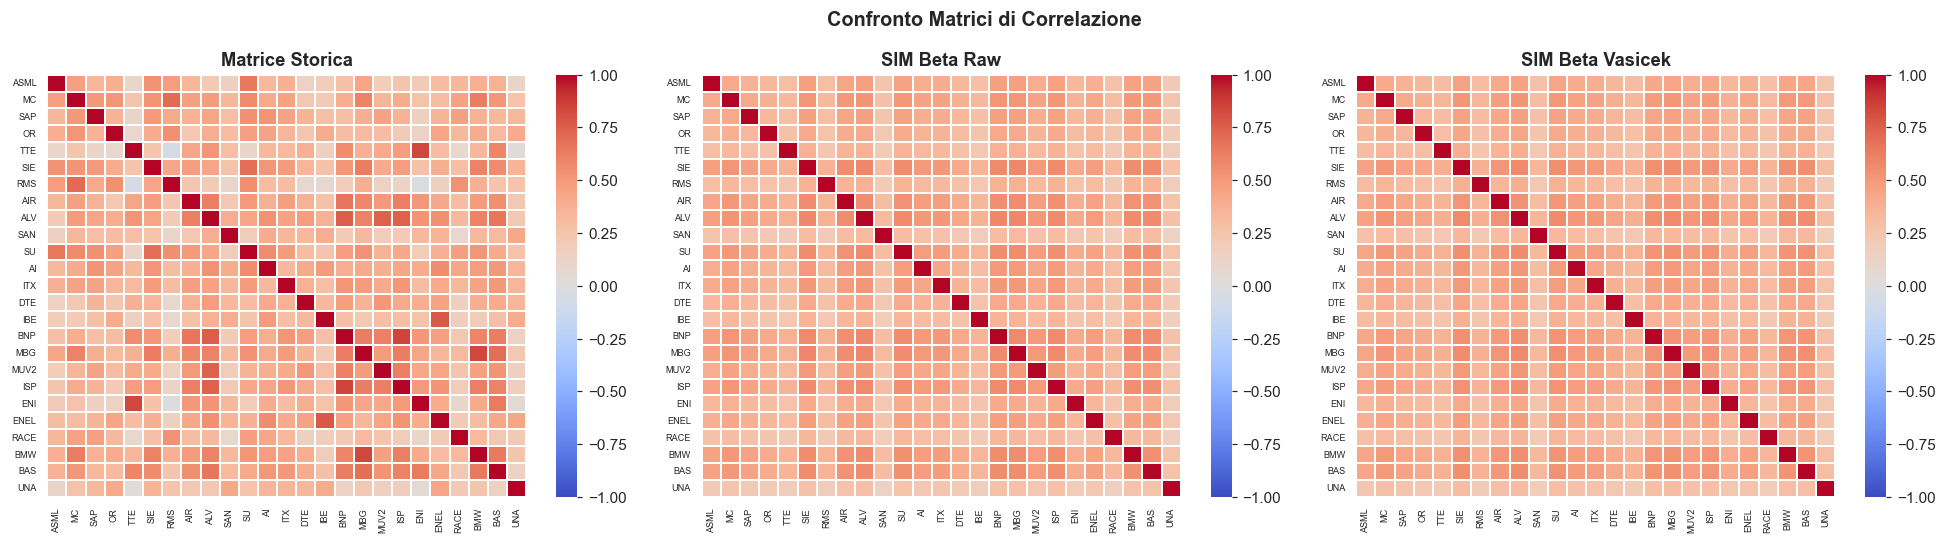

In [14]:
std_stocks = log_ret.std().values * np.sqrt(FREQ)
std_prod   = np.outer(std_stocks, std_stocks)  # matrice dei prodotti delle volatilità

# Correlazione implicita SIM: rho_ij = beta_i * beta_j * var_m / (sigma_i * sigma_j)
corr_sim_raw = (np.outer(betas, betas) * var_m) / std_prod
np.fill_diagonal(corr_sim_raw, 1.0)

corr_sim_vas_arr = (np.outer(betas_vasicek, betas_vasicek) * var_m) / std_prod
np.fill_diagonal(corr_sim_vas_arr, 1.0)

# Aggiustamento per ancorare la media della matrice SIM al livello storico
idx_upper      = np.triu_indices(n_assets, k=1)
mean_corr_hist = np.mean(corr_matrix.values[idx_upper])

corr_sim_raw_adj = np.clip(
    corr_sim_raw[idx_upper] - np.mean(corr_sim_raw[idx_upper]) + mean_corr_hist, -1.0, 1.0)
corr_sim_vas_adj = np.clip(
    corr_sim_vas_arr[idx_upper] - np.mean(corr_sim_vas_arr[idx_upper]) + mean_corr_hist, -1.0, 1.0)

# MSE: misura quanto la matrice SIM si discosta da quella storica
corr_hist_vals = corr_matrix.values[idx_upper]
mse_raw = np.mean((corr_sim_raw_adj - corr_hist_vals)**2)
mse_vas = np.mean((corr_sim_vas_adj - corr_hist_vals)**2)

print('=== MSE MATRICE DI CORRELAZIONE ===')
print(f'SIM Beta Raw     : {mse_raw:.6f}')
print(f'SIM Beta Vasicek : {mse_vas:.6f}')
print(f'\nCorrelazione media storica: {mean_corr_hist:.4f}')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, mat, title in zip(axes,
    [corr_matrix.values, corr_sim_raw, corr_sim_vas_arr],
    ['Matrice Storica', 'SIM Beta Raw', 'SIM Beta Vasicek']):
    sns.heatmap(mat, ax=ax, cmap='coolwarm', vmin=-1, vmax=1,
                xticklabels=[c.upper() for c in log_ret.columns],
                yticklabels=[c.upper() for c in log_ret.columns],
                annot=False, linewidths=0.1)
    ax.set_title(title, fontweight='bold')
    ax.tick_params(labelsize=6)
plt.suptitle('Confronto Matrici di Correlazione', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 2.6 – Simulazione Monte Carlo dell'opportunity set
Generazione di 35.000 portafogli casuali per mappare lo spazio rischio-rendimento raggiungibile.


In [15]:
# Simulazione di 35.000 portafogli casuali: pesi uniformi normalizzati, senza cap individuale
num_ports   = 35000
all_weights = np.zeros((num_ports, n_assets))
ret_arr     = np.zeros(num_ports)
vol_arr     = np.zeros(num_ports)
sharpe_arr  = np.zeros(num_ports)

mu_vec_sim  = mu_sim.values
cov_mat_sim = cov_sim.values

for ind in range(num_ports):
    weights = np.random.random(n_assets)
    weights = weights / np.sum(weights)  # normalizzazione: somma pesi = 1
    all_weights[ind, :] = weights
    ret_arr[ind]    = np.sum(mu_vec_sim * weights)
    vol_arr[ind]    = np.sqrt(np.dot(weights.T, np.dot(cov_mat_sim, weights)))
    sharpe_arr[ind] = (ret_arr[ind] - rf_annuo) / vol_arr[ind]

max_sr_idx = sharpe_arr.argmax()
print(f'MC – Max Sharpe (approx.): {sharpe_arr[max_sr_idx]:.4f}')
print(f'  Rendimento : {ret_arr[max_sr_idx]:.2%}')
print(f'  Volatilità : {vol_arr[max_sr_idx]:.2%}')


MC – Max Sharpe (approx.): 0.5608
  Rendimento : 11.39%
  Volatilità : 14.96%


### 2.7 – Portafogli di tangenza (ottimizzazione SLSQP)
Massimizzazione dello Sharpe Ratio su tre set di input: storico, SIM beta raw, SIM beta Vasicek.


In [16]:
mu_hist_arr  = mu_hist.values
cov_hist_arr = cov_hist.values

# Massimizzazione Sharpe su input storici
res_tang_hist = sco.minimize(
    neg_sharpe, w0,
    args=(mu_hist_arr, cov_hist_arr, rf_annuo),
    method='SLSQP', bounds=bounds, constraints=constraints
)

# Massimizzazione Sharpe su input SIM (beta raw)
res_tang_sim = sco.minimize(
    neg_sharpe, w0,
    args=(mu_vec_sim, cov_mat_sim, rf_annuo),
    method='SLSQP', bounds=bounds, constraints=constraints
)

# Massimizzazione Sharpe su input SIM con beta Vasicek-adjusted
res_tang_vas = sco.minimize(
    neg_sharpe, w0,
    args=(mu_sim_vas.values, cov_sim_vas.values, rf_annuo),
    method='SLSQP', bounds=bounds, constraints=constraints
)

print(f'Tangenza Storico  – Sharpe: {-res_tang_hist.fun:.4f} | Conv: {res_tang_hist.success}')
print(f'Tangenza SIM      – Sharpe: {-res_tang_sim.fun:.4f} | Conv: {res_tang_sim.success}')
print(f'Tangenza SIM+Vas  – Sharpe: {-res_tang_vas.fun:.4f} | Conv: {res_tang_vas.success}')


Tangenza Storico  – Sharpe: 0.7254 | Conv: True
Tangenza SIM      – Sharpe: 0.7416 | Conv: True
Tangenza SIM+Vas  – Sharpe: 0.7364 | Conv: True


### 2.8 – Global Minimum Variance
Minimizzazione della volatilità di portafoglio senza vincolo sul rendimento atteso.


In [17]:
# Minimizzazione della varianza di portafoglio: non viene imposto alcun target di rendimento
res_gmv = sco.minimize(
    minimize_volatility, w0,
    args=(cov_mat_sim,),
    method='SLSQP', bounds=bounds, constraints=constraints
)
print(f'GMV – Volatilità min: {res_gmv.fun:.2%} | Conv: {res_gmv.success}')


GMV – Volatilità min: 12.31% | Conv: True


### 2.9 – Selezione ottimale con cutoff C*
Algoritmo di Elton-Gruber: ordinamento per excess return/beta e calcolo cumulativo di C_i fino al cutoff C*.


In [18]:
# Costruzione DataFrame ordinato per excess return / beta decrescente
df_cstar = pd.DataFrame({
    'Mean return'       : mu_sim.values,
    'Beta'              : betas,
    'Idiosyncratic risk': resid_vars
}, index=log_ret.columns)

df_cstar['Excess return']           = df_cstar['Mean return'] - rf_annuo
df_cstar['Excess return over beta'] = df_cstar['Excess return'] / df_cstar['Beta']

df_cstar = df_cstar.sort_values('Excess return over beta', ascending=False).reset_index()
df_cstar.rename(columns={'index': 'Asset'}, inplace=True)

# Calcolo cumulativo di C_i:
#   Num: sigma_m^2 * sum( (R_j - R_f) * beta_j / sigma_ej^2 )
#   Den: 1 + sigma_m^2 * sum( beta_j^2 / sigma_ej^2 )
df_cstar['np1']     = df_cstar['Excess return'] * df_cstar['Beta'] / df_cstar['Idiosyncratic risk']
df_cstar['np1_sum'] = df_cstar['np1'].cumsum() * var_m
df_cstar['dp1']     = df_cstar['Beta']**2 / df_cstar['Idiosyncratic risk']
df_cstar['dp1_sum'] = 1 + var_m * df_cstar['dp1'].cumsum()
df_cstar['C']       = df_cstar['np1_sum'] / df_cstar['dp1_sum']

print('=== CALCOLO C_i ===')
print(df_cstar[['Asset','Excess return over beta','C']].to_string(index=False))


=== CALCOLO C_i ===
Asset  Excess return over beta        C
 race                 0.239756 0.047232
 asml                 0.205750 0.098095
  rms                 0.180031 0.109851
  ibe                 0.161387 0.115841
 muv2                 0.109409 0.114333
   su                 0.108532 0.112763
   ai                 0.105534 0.111704
   mc                 0.083838 0.107570
   or                 0.080594 0.105765
 enel                 0.069942 0.102496
  dte                 0.065669 0.100356
  alv                 0.057548 0.093459
  sie                 0.053505 0.088127
  air                 0.053000 0.084625
  sap                 0.049147 0.082887
  tte                 0.044920 0.081932
  isp                 0.030565 0.077093
  eni                 0.029830 0.075688
  itx                 0.025191 0.073029
  bnp                 0.016392 0.068275
  mbg                -0.020718 0.061251
  bmw                -0.027661 0.055693
  san                -0.033274 0.054740
  una               

In [19]:
# Asset inclusi: quelli con excess return/beta > C_i cumulativo al proprio rango
df_cstar_included = df_cstar[df_cstar['Excess return over beta'] > df_cstar['C']].copy()
C_star = df_cstar_included['C'].max()  # soglia finale C*

print(f'C* = {C_star:.4f}')
print(f'Asset inclusi: {len(df_cstar_included)}')
print(df_cstar_included[['Asset','Excess return over beta','C']].to_string(index=False))

# Pesi Z_i proporzionali alla distanza (excess return/beta - C*) ponderata per beta/sigma_e^2
df_cstar_included['Z'] = (
    df_cstar_included['Beta'] / df_cstar_included['Idiosyncratic risk'] *
    (df_cstar_included['Excess return over beta'] - C_star)
)
df_cstar_included['X'] = df_cstar_included['Z'] / df_cstar_included['Z'].sum()  # normalizzazione

# Mappatura dei pesi sul vettore completo degli n_assets (0 per gli asset esclusi)
w_cstar = np.zeros(n_assets)
for _, row in df_cstar_included.iterrows():
    idx_asset = list(log_ret.columns).index(row['Asset'])
    w_cstar[idx_asset] = row['X']

print('\n=== PESI PORTAFOGLIO C* ===')
print(df_cstar_included[['Asset','Z','X']].round(4).to_string(index=False))


C* = 0.1158
Asset inclusi: 4
Asset  Excess return over beta        C
 race                 0.239756 0.047232
 asml                 0.205750 0.098095
  rms                 0.180031 0.109851
  ibe                 0.161387 0.115841

=== PESI PORTAFOGLIO C* ===
Asset      Z      X
 race 1.6082 0.3047
 asml 1.7819 0.3376
  rms 0.9875 0.1871
  ibe 0.9010 0.1707


### 2.10 – Frontiera efficiente
Calcolo del ramo efficiente della frontiera (post-GMV) tramite minimizzazione della volatilità per rendimento target.


In [20]:
# Per ogni rendimento target: minimizza la volatilità -> traccia la frontiera media-varianza
def compute_frontier(mu_arr, cov_arr, asset_bounds, n_points=80):
    n      = len(mu_arr)
    w_init = np.array([1/n]*n)
    frontier_y   = np.linspace(mu_arr.min(), mu_arr.max(), n_points)
    frontier_vol = []
    valid_ret    = []

    for tr in frontier_y:
        cons = (
            {'type': 'eq', 'fun': lambda x: np.sum(x) - 1},
            {'type': 'eq', 'fun': lambda x, tr=tr: np.sum(x * mu_arr) - tr}
        )
        res = sco.minimize(
            lambda w, c=cov_arr: np.sqrt(np.dot(w.T, np.dot(c, w))),
            w_init, method='SLSQP', bounds=asset_bounds, constraints=cons
        )
        if res.success:
            frontier_vol.append(res.fun)
            valid_ret.append(tr)

    # Identificazione del ramo efficiente: inizia dal GMV (i_min) e termina dove la frontiera si appiattisce
    vols = np.array(frontier_vol)
    rets = np.array(valid_ret)
    i_min, i_max = 0, len(vols)
    for i in range(1, len(vols)):
        if i_min == 0 and vols[i-1] - vols[i] <= 0:
            i_min = i
        if abs(vols[i-1] - vols[i]) <= 1e-10 and i_max == len(vols):
            i_max = i
    return vols, rets, i_min, i_max

print('Calcolo frontiera storica...')
vols_hist, rets_hist, imin_h, imax_h = compute_frontier(mu_hist_arr, cov_hist_arr, bounds)
print('Calcolo frontiera SIM...')
vols_sim,  rets_sim,  imin_s, imax_s  = compute_frontier(mu_vec_sim,  cov_mat_sim,  bounds)
print('Frontiere calcolate.')


Calcolo frontiera storica...
Calcolo frontiera SIM...
Frontiere calcolate.


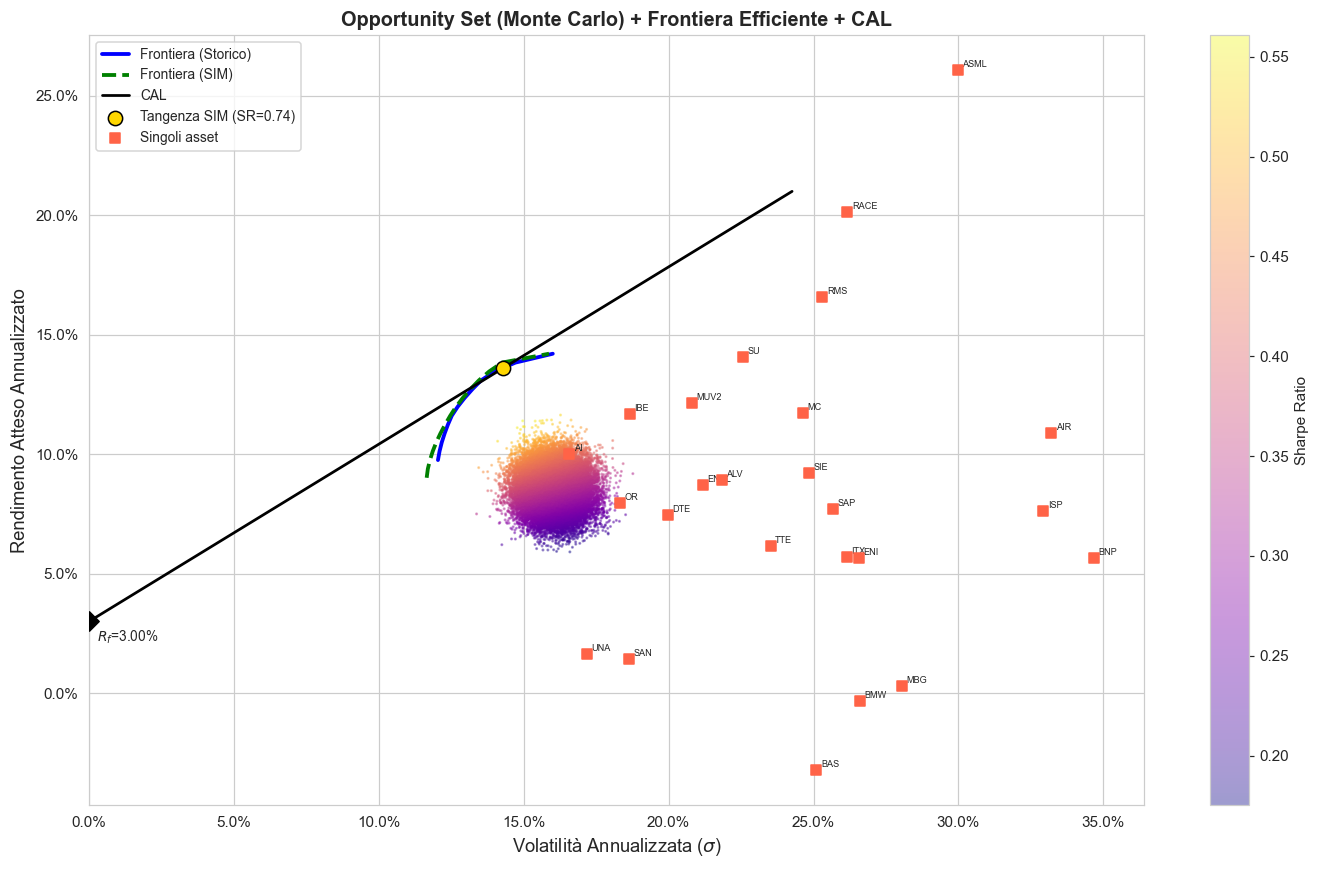

In [21]:
# Metriche del portafoglio di tangenza SIM per il grafico
w_T   = res_tang_sim.x
ret_T = np.sum(w_T * mu_vec_sim)
vol_T = np.sqrt(np.dot(w_T, np.dot(cov_mat_sim, w_T)))
sr_T  = (ret_T - rf_annuo) / vol_T

# Capital Allocation Line: R_f + Sharpe * sigma
slope = (ret_T - rf_annuo) / vol_T
cal_x = np.linspace(0, vol_T * 1.7, 80)
cal_y = rf_annuo + slope * cal_x

fig, ax = plt.subplots(figsize=(13, 8))

# Nuvola Monte Carlo colorata per Sharpe Ratio
sc = ax.scatter(vol_arr, ret_arr, c=sharpe_arr, cmap='plasma', s=1, alpha=0.4, zorder=1)
plt.colorbar(sc, ax=ax, label='Sharpe Ratio')

ax.plot(vols_hist[imin_h:imax_h], rets_hist[imin_h:imax_h],
        'b-', linewidth=2.5, zorder=3, label='Frontiera (Storico)')
ax.plot(vols_sim[imin_s:imax_s], rets_sim[imin_s:imax_s],
        'g--', linewidth=2.5, zorder=3, label='Frontiera (SIM)')
ax.plot(cal_x, cal_y, 'k-', linewidth=1.8, zorder=4, label='CAL')

ax.scatter(0, rf_annuo, marker='D', color='black', s=80, zorder=6)
ax.annotate(f'$R_f$={rf_annuo:.2%}', (0, rf_annuo),
            textcoords='offset points', xytext=(5,-13), fontsize=9)

ax.scatter(vol_T, ret_T, marker='.', color='gold', edgecolors='black',
           s=350, zorder=7, label=f'Tangenza SIM (SR={sr_T:.2f})')

# Posizionamento dei singoli asset nello spazio rischio-rendimento
asset_vols = np.sqrt(np.diag(cov_mat_sim))
ax.scatter(asset_vols, mu_vec_sim, marker='s', color='tomato', s=50, zorder=5, label='Singoli asset')
for i, col in enumerate(log_ret.columns):
    ax.annotate(col.upper(), (asset_vols[i], mu_vec_sim[i]),
                textcoords='offset points', xytext=(3,2), fontsize=6)

ax.set_xlabel('Volatilità Annualizzata ($\sigma$)', fontsize=12)
ax.set_ylabel('Rendimento Atteso Annualizzato', fontsize=12)
ax.set_title('Opportunity Set (Monte Carlo) + Frontiera Efficiente + CAL',
             fontsize=13, fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y,_: f'{y:.1%}'))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'{x:.1%}'))
ax.set_xlim(left=0)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


### 2.11 – Criterio di Kataoka (Safety First)
Il criterio di Kataoka massimizza il rendimento minimo garantito R_m al livello di confidenza (1-\alpha)


In [22]:
from scipy.stats import norm

# Quantile z corrispondente al livello di confidenza 95% (alpha = 5%)
ALPHA_KATAOKA = 0.05
z_alpha = norm.ppf(1 - ALPHA_KATAOKA)  # z = 1.6449

# Funzione obiettivo: massimizza R_m = mu_P - z * sigma_P (floor garantito al 95%)
def neg_rm(weights, mu_vec, cov_mat, z):
    weights = np.array(weights)
    ret = np.dot(weights, mu_vec)
    vol = np.sqrt(np.dot(weights.T, np.dot(cov_mat, weights)))
    return -(ret - z * vol)  # negato per la minimizzazione

# Ottimizzazione su input SIM+Vasicek con vincoli settoriali
res_kataoka = sco.minimize(
    neg_rm, w0,
    args=(mu_sim_vas.values, cov_sim_vas.values, z_alpha),
    method='SLSQP', bounds=bounds, constraints=constraints
)

w_kataoka = res_kataoka.x
ret_kat   = np.dot(w_kataoka, mu_sim_vas.values)
vol_kat   = np.sqrt(np.dot(w_kataoka, np.dot(cov_sim_vas.values, w_kataoka)))
rm_kat    = ret_kat - z_alpha * vol_kat  # rendimento minimo garantito al 95%
sr_kat    = (ret_kat - rf_annuo) / vol_kat

print(f'=== CRITERIO DI KATAOKA (alpha = {ALPHA_KATAOKA:.0%}, z = {z_alpha:.4f}) ===')
print(f'Rendimento atteso (ann.) : {ret_kat:.2%}')
print(f'Volatilità (ann.)        : {vol_kat:.2%}')
print(f'Sharpe Ratio             : {sr_kat:.4f}')
print(f'R_m garantito al {(1-ALPHA_KATAOKA):.0%} : {rm_kat:.2%}')
print(f'Conv.: {res_kataoka.success}')
print()
pesi_kat_series = pd.Series(w_kataoka, index=log_ret.columns).sort_values(ascending=False)
print('--- PESI PORTAFOGLIO KATAOKA ---')
print(pesi_kat_series[pesi_kat_series > 0.001].apply(lambda x: f'{x:.2%}').to_string())


=== CRITERIO DI KATAOKA (alpha = 5%, z = 1.6449) ===
Rendimento atteso (ann.) : 12.29%
Volatilità (ann.)        : 13.26%
Sharpe Ratio             : 0.7005
R_m garantito al 95% : -9.52%
Conv.: True

--- PESI PORTAFOGLIO KATAOKA ---
asml    10.00%
muv2    10.00%
race    10.00%
una     10.00%
ibe     10.00%
rms     10.00%
or      10.00%
dte     10.00%
su       8.50%
san      6.50%
ai       5.00%


### 2.12 – Criterio Value-at-Risk Monte Carlo
Il VaR MC massimizza il 5° percentile empirico dei rendimenti storici del portafoglio.
Differenza chiave rispetto a Kataoka: utilizza la distribuzione empirica invece della formula parametrica.


In [23]:
ALPHA_VAR = 0.05

ret_matrix = log_ret.values  # matrice (n_obs x n_assets) dei log-rendimenti storici mensili

# Funzione obiettivo: massimizza il 5° percentile empirico dei rendimenti del portafoglio
# Non assume normalità: usa i dati storici direttamente
def neg_var_mc(weights, ret_mat, alpha):
    weights  = np.array(weights)
    port_ret = ret_mat @ weights                           # rendimento storico del portafoglio
    return -np.percentile(port_ret, alpha * 100)           # percentile empirico negato

bounds_free = tuple((0.0, 1.0) for _ in range(n_assets))  # versione long-only senza cap

scenarios_var_mc = [
    ('VaR MC – libero',    bounds_free, [cons_sum1]),
    ('VaR MC – vincolato', bounds,      constraints),
]

results_var_mc = {}
for label, bnd, con in scenarios_var_mc:
    res = sco.minimize(
        neg_var_mc, w0,
        args=(ret_matrix, ALPHA_VAR),
        method='SLSQP', bounds=bnd, constraints=con
    )
    w             = res.x
    port_ret_hist = ret_matrix @ w
    var_mc_mens   = np.percentile(port_ret_hist, ALPHA_VAR * 100)   # VaR mensile empirico
    var_mc_ann    = var_mc_mens * np.sqrt(FREQ)                      # annualizzazione
    ret_p         = np.dot(w, mu_sim_vas.values)
    vol_p         = np.sqrt(np.dot(w, np.dot(cov_sim_vas.values, w)))
    sr_p          = (ret_p - rf_annuo) / vol_p
    results_var_mc[label] = {
        'weights': w, 'ret': ret_p, 'vol': vol_p,
        'VaR MC (ann.)': var_mc_ann, 'VaR MC (mens.)': var_mc_mens,
        'port_ret_hist': port_ret_hist, 'Sharpe': sr_p, 'conv': res.success
    }
    print(f'{label:<28} | Ret={ret_p:.2%} | Vol={vol_p:.2%} '
          f'| VaR MC (ann.)={var_mc_ann:.2%} | SR={sr_p:.3f} | Conv={res.success}')

# Portafoglio selezionato: VaR MC vincolato (vincoli settoriali + cap individuale)
w_var_mc       = results_var_mc['VaR MC – vincolato']['weights']
ret_varmc      = results_var_mc['VaR MC – vincolato']['ret']
vol_varmc      = results_var_mc['VaR MC – vincolato']['vol']
var_mc_ann_sel = results_var_mc['VaR MC – vincolato']['VaR MC (ann.)']
sr_varmc       = results_var_mc['VaR MC – vincolato']['Sharpe']


VaR MC – libero              | Ret=10.22% | Vol=14.29% | VaR MC (ann.)=-14.39% | SR=0.505 | Conv=True
VaR MC – vincolato           | Ret=8.93% | Vol=13.91% | VaR MC (ann.)=-13.38% | SR=0.426 | Conv=True


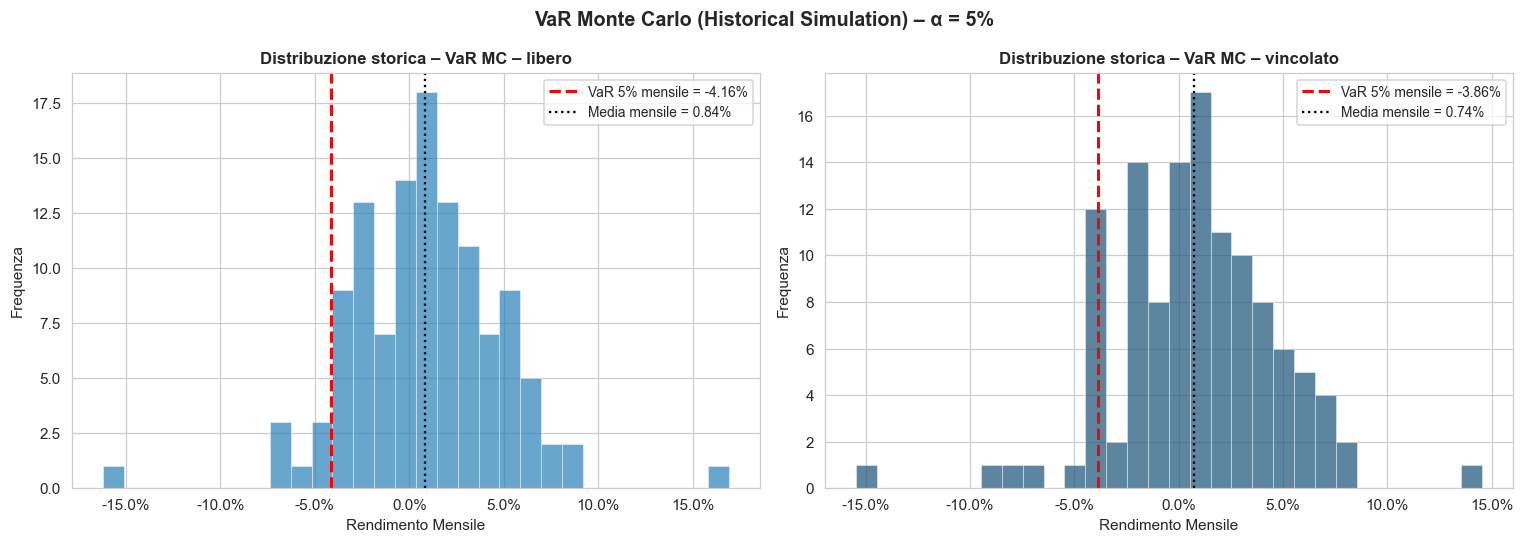

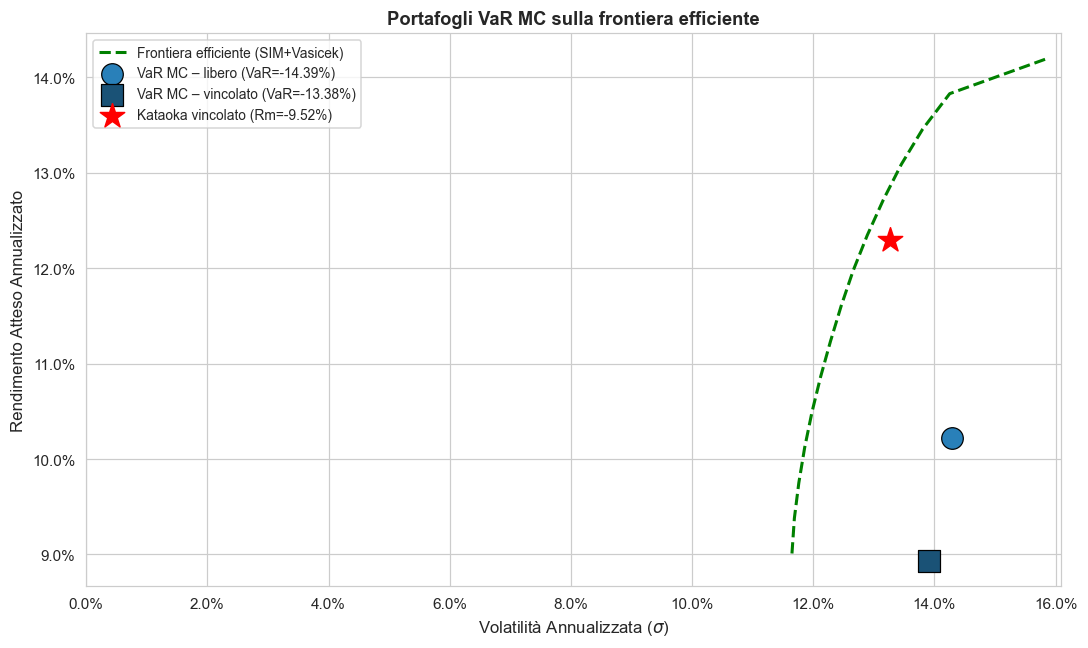

In [24]:
# Istogrammi dei rendimenti storici: distribuzione empirica con VaR al 5% evidenziato
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors_mc = ['#2980b9', '#1a5276']

for ax, (label, d), col in zip(axes, results_var_mc.items(), colors_mc):
    port_ret = d['port_ret_hist']
    var_m    = d['VaR MC (mens.)']
    ax.hist(port_ret, bins=30, color=col, alpha=0.7, edgecolor='white', linewidth=0.4)
    ax.axvline(var_m, color='red', linestyle='--', linewidth=2,
               label=f'VaR 5% mensile = {var_m:.2%}')     # soglia del peggiore 5% degli scenari
    ax.axvline(port_ret.mean(), color='black', linestyle=':', linewidth=1.5,
               label=f'Media mensile = {port_ret.mean():.2%}')
    ax.set_title(f'Distribuzione storica – {label}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Rendimento Mensile')
    ax.set_ylabel('Frequenza')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
    ax.legend(fontsize=9)
plt.suptitle(f'VaR Monte Carlo (Historical Simulation) – α = {ALPHA_VAR:.0%}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Posizionamento dei portafogli VaR MC sulla frontiera efficiente per confronto visivo
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(vols_sim[imin_s:imax_s], rets_sim[imin_s:imax_s],
        'g--', linewidth=2, label='Frontiera efficiente (SIM+Vasicek)')
for (label, d), col, mk in zip(results_var_mc.items(), colors_mc, ['o', 's']):
    ax.scatter(d['vol'], d['ret'], marker=mk, color=col, s=200, zorder=5,
               edgecolors='black', lw=0.8,
               label=f"{label} (VaR={d['VaR MC (ann.)']:.2%})")
ax.scatter(vol_kat, ret_kat, marker='*', color='red', s=280, zorder=5,
           label=f'Kataoka vincolato (Rm={rm_kat:.2%})')
ax.set_xlabel(r'Volatilità Annualizzata ($\sigma$)', fontsize=11)
ax.set_ylabel('Rendimento Atteso Annualizzato', fontsize=11)
ax.set_title('Portafogli VaR MC sulla frontiera efficiente', fontsize=12, fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.1%}'))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
ax.set_xlim(left=0)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


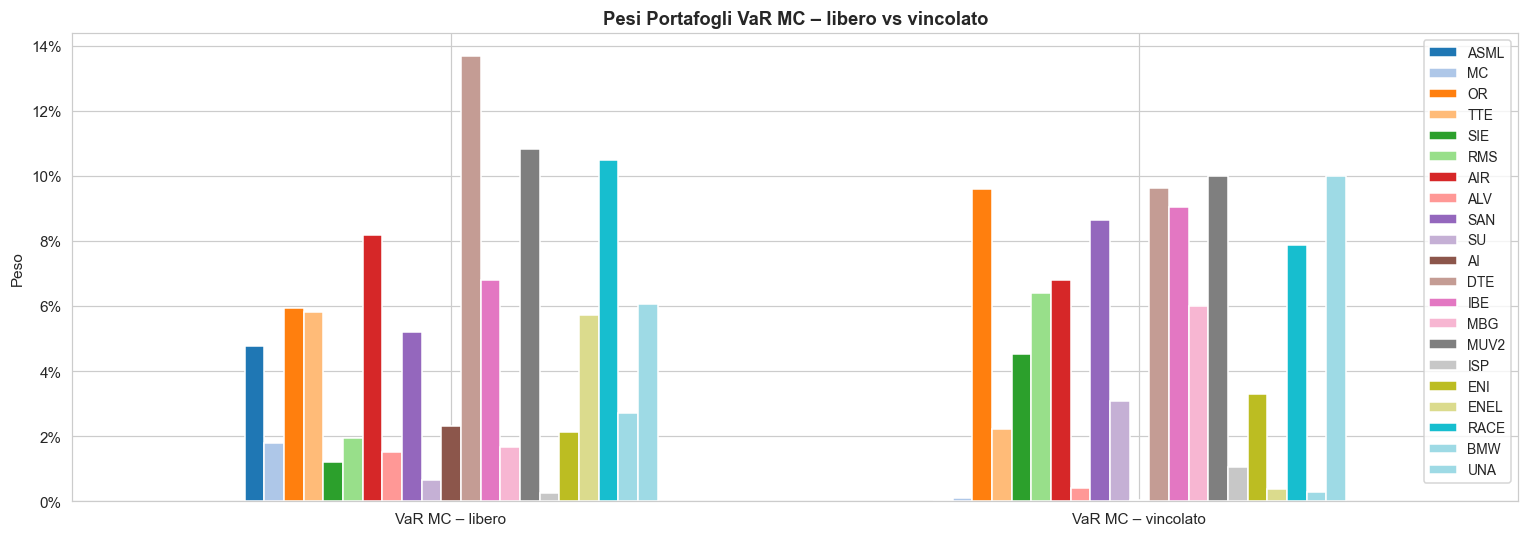

=== VERIFICA VINCOLI SETTORIALI – VaR MC vincolato ===
  Settore Energy : 15.00% (cap 15%)
  Settore Auto   : 14.20% (cap 15%)
  Peso massimo   : 10.00%


In [25]:
# Grafico a barre dei pesi: libero vs vincolato, solo asset con peso > 0.5%
pesi_var_mc_df   = pd.DataFrame(
    {label: d['weights'] for label, d in results_var_mc.items()},
    index=[c.upper() for c in log_ret.columns]
)
pesi_var_mc_plot = pesi_var_mc_df[pesi_var_mc_df.max(axis=1) > 0.005]
ax = pesi_var_mc_plot.T.plot(kind='bar', figsize=(14, 5), colormap='tab20',
                              edgecolor='white', width=0.6)
ax.set_title('Pesi Portafogli VaR MC – libero vs vincolato', fontsize=12, fontweight='bold')
ax.set_ylabel('Peso')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Verifica del rispetto dei vincoli settoriali nella variante vincolata
energy_idx = [i for i, c in enumerate(log_ret.columns) if c in ENERGY_COLS]
auto_idx   = [i for i, c in enumerate(log_ret.columns) if c in AUTO_COLS]
w_vc = results_var_mc['VaR MC – vincolato']['weights']
print('=== VERIFICA VINCOLI SETTORIALI – VaR MC vincolato ===')
print(f'  Settore Energy : {w_vc[energy_idx].sum():.2%} (cap {CAP_SECTOR_ENERGY:.0%})')
print(f'  Settore Auto   : {w_vc[auto_idx].sum():.2%} (cap {CAP_SECTOR_AUTO:.0%})')
print(f'  Peso massimo   : {w_vc.max():.2%}')


### 2.12b – Confronto Kataoka vs VaR Monte Carlo

| Aspetto | Kataoka | VaR Monte Carlo |
|---|---|---|
| Distribuzione assunta | Normale | Empirica (storica) |
| Metodo | Parametrico: $\mu_P - z_\alpha \sigma_P$ | Non-parametrico: percentile storico |
| Obiettivo | Massimizza floor analitico | Massimizza floor empirico |


In [ ]:
# Ottimizzazione Kataoka su 2 scenari (libero/vincolato) per confronto simmetrico con VaR MC
scenarios_kat_conf = [
    ('Kataoka – libero',    bounds_free, [cons_sum1]),
    ('Kataoka – vincolato', bounds,      constraints),
]
results_kat_conf = {}
for label, bnd, con in scenarios_kat_conf:
    res = sco.minimize(
        neg_rm, w0,
        args=(mu_sim_vas.values, cov_sim_vas.values, z_alpha),
        method='SLSQP', bounds=bnd, constraints=con
    )
    w     = res.x
    ret_p = np.dot(w, mu_sim_vas.values)
    vol_p = np.sqrt(np.dot(w, np.dot(cov_sim_vas.values, w)))
    rm_p  = ret_p - z_alpha * vol_p                                  # floor parametrico
    sr_p  = (ret_p - rf_annuo) / vol_p
    # VaR MC calcolato anche sul portafoglio Kataoka per confronto apples-to-apples 
    var_mc_kat = np.percentile(ret_matrix @ w, ALPHA_VAR * 100) * np.sqrt(FREQ)
    results_kat_conf[label] = {
        'weights': w, 'ret': ret_p, 'vol': vol_p,
        'Rm (Kataoka)': rm_p, 'VaR MC (ann.)': var_mc_kat,
        'Sharpe': sr_p, 'conv': res.success
    }

# Tabella riepilogativa: 4 righe (2 Kataoka + 2 VaR MC) con metriche uniformi
rows_conf = []
for label, d in results_kat_conf.items():
    w = d['weights']
    rows_conf.append({
        'Criterio'        : 'Kataoka',
        'Scenario'        : label,
        'Rend. Atteso'    : f"{d['ret']:.2%}",
        'Volatilità'       : f"{d['vol']:.2%}",
        'Sharpe Ratio'    : f"{d['Sharpe']:.4f}",
        'Rm parametrico'  : f"{d['Rm (Kataoka)']:.2%}",
        'VaR MC (ann.)'   : f"{d['VaR MC (ann.)']:.2%}",
        'HHI'             : f"{hhi(w):.4f}",
        'N° asset attivi'  : int((w > 0.01).sum()),
        'Peso max'        : f"{w.max():.2%}",
    })
for label, d in results_var_mc.items():
    w = d['weights']
    rows_conf.append({
        'Criterio'        : 'VaR MC',
        'Scenario'        : label,
        'Rend. Atteso'    : f"{d['ret']:.2%}",
        'Volatilità'       : f"{d['vol']:.2%}",
        'Sharpe Ratio'    : f"{d['Sharpe']:.4f}",
        'Rm parametrico'  : 'n/a',
        'VaR MC (ann.)'   : f"{d['VaR MC (ann.)']:.2%}",
        'HHI'             : f"{hhi(w):.4f}",
        'N° asset attivi'  : int((w > 0.01).sum()),
        'Peso max'        : f"{w.max():.2%}",
    })

df_conf = pd.DataFrame(rows_conf).set_index(['Criterio','Scenario'])
print('=== CONFRONTO KATAOKA vs VaR MONTE CARLO ===')
print(df_conf.to_string())


=== CONFRONTO KATAOKA vs VaR MONTE CARLO ===
                             Rend. Atteso Volatilità Sharpe Ratio Rm parametrico VaR MC (ann.)     HHI  N° asset attivi Peso max
Criterio Scenario                                                                                                               
Kataoka  Kataoka – libero          15.41%     14.38%       0.8623         -8.25%       -19.07%  0.1623                8   23.35%
         Kataoka – vincolato       12.29%     13.26%       0.7005         -9.52%       -16.22%  0.0940               11   10.00%
VaR MC   VaR MC – libero           10.22%     14.29%       0.5049            n/a       -14.39%  0.0748               19   13.70%
         VaR MC – vincolato         8.93%     13.91%       0.4264            n/a       -13.38%  0.0776               15   10.00%


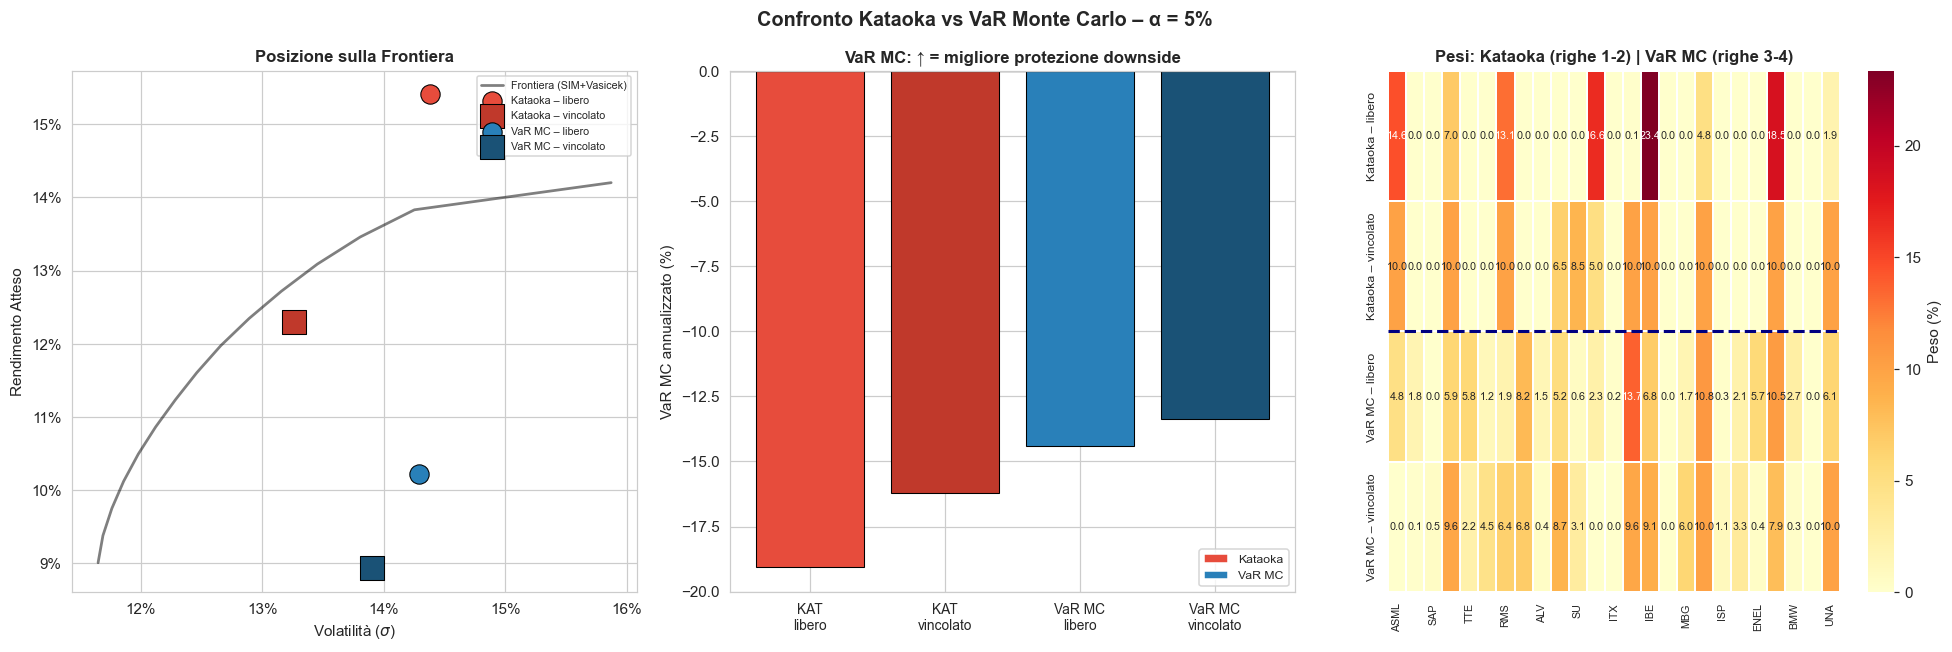

In [27]:
# Tre pannelli: (1) posizione sulla frontiera, (2) VaR MC comparativo, (3) heatmap pesi
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors_kat = ['#e74c3c', '#c0392b']
colors_vmc = ['#2980b9', '#1a5276']
markers = ['o', 's']
sizes   = [160, 260]  # marker più grande = variante vincolata

ax = axes[0]
ax.plot(vols_sim[imin_s:imax_s], rets_sim[imin_s:imax_s],
        'k-', lw=1.8, alpha=0.5, label='Frontiera (SIM+Vasicek)')
for (label, d), col, mk, sz in zip(results_kat_conf.items(), colors_kat, markers, sizes):
    ax.scatter(d['vol'], d['ret'], marker=mk, color=col, s=sz,
               edgecolors='black', lw=0.7, zorder=5, label=label)
for (label, d), col, mk, sz in zip(results_var_mc.items(), colors_vmc, markers, sizes):
    ax.scatter(d['vol'], d['ret'], marker=mk, color=col, s=sz,
               edgecolors='black', lw=0.7, zorder=5, label=label)
ax.set_xlabel(r'Volatilità ($\sigma$)', fontsize=10)
ax.set_ylabel('Rendimento Atteso', fontsize=10)
ax.set_title('Posizione sulla Frontiera', fontsize=11, fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax.legend(fontsize=7)

# VaR MC annualizzato per ciascuno scenario: valore più alto = migliore protezione downside
ax2 = axes[1]
all_labels = list(results_kat_conf.keys()) + list(results_var_mc.keys())
all_var_mc = ([d['VaR MC (ann.)'] for d in results_kat_conf.values()] +
              [d['VaR MC (ann.)'] for d in results_var_mc.values()])
all_colors = colors_kat + colors_vmc
short_lbl  = [l.replace('Kataoka – ','KAT\n').replace('VaR MC – ','VaR MC\n')
              for l in all_labels]
ax2.bar(short_lbl, [v*100 for v in all_var_mc],
        color=all_colors, edgecolor='black', linewidth=0.7)
ax2.axhline(0, color='black', lw=0.8)
ax2.set_ylabel('VaR MC annualizzato (%)')
ax2.set_title('VaR MC: ↑ = migliore protezione downside', fontsize=11, fontweight='bold')
ax2.tick_params(axis='x', labelsize=9)

# Heatmap dei pesi: righe = portafogli, colonne = asset
ax3 = axes[2]
all_w_df = pd.DataFrame(
    {**{l: d['weights'] for l, d in results_kat_conf.items()},
     **{l: d['weights'] for l, d in results_var_mc.items()}},
    index=[c.upper() for c in log_ret.columns]
)
sns.heatmap(all_w_df.T * 100, ax=ax3, cmap='YlOrRd',
            annot=True, fmt='.1f', annot_kws={'size': 7},
            linewidths=0.3, cbar_kws={'label': 'Peso (%)'})
ax3.axhline(2, color='navy', lw=2, linestyle='--')  # separatore Kataoka / VaR MC
ax3.set_title('Pesi: Kataoka (righe 1-2) | VaR MC (righe 3-4)', fontsize=11, fontweight='bold')
ax3.tick_params(axis='x', labelsize=7)
ax3.tick_params(axis='y', labelsize=8)

from matplotlib.patches import Patch
legend_p = [Patch(facecolor='#e74c3c', label='Kataoka'),
            Patch(facecolor='#2980b9', label='VaR MC')]
axes[1].legend(handles=legend_p, fontsize=8)

plt.suptitle(f'Confronto Kataoka vs VaR Monte Carlo – α = {ALPHA_VAR:.0%}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 2.13 – Tabella comparativa portafogli
Riepilogo di tutti i portafogli candidati con rendimento, volatilità, Sharpe, HHI e numero di asset attivi.


In [28]:
# Dizionario di tutti i portafogli candidati con i rispettivi input di stima
portfolios = {
    'Tangenza Storico'  : (res_tang_hist.x,  mu_hist_arr,       cov_hist_arr),
    'Tangenza SIM'      : (res_tang_sim.x,   mu_vec_sim,        cov_mat_sim),
    'Tangenza SIM+Vas'  : (res_tang_vas.x,   mu_sim_vas.values, cov_sim_vas.values),
    'Kataoka (α=5%)'    : (w_kataoka,         mu_sim_vas.values, cov_sim_vas.values),
    'VaR MC (vincolato)': (w_var_mc,          mu_sim_vas.values, cov_sim_vas.values),
    'GMV (SIM)'         : (res_gmv.x,         mu_vec_sim,        cov_mat_sim),
    'C* (L02)'          : (w_cstar,            mu_vec_sim,        cov_mat_sim),
    'Equal Weight'      : (np.array([1/n_assets]*n_assets), mu_vec_sim, cov_mat_sim),
}

rows = []
for nome, (w, mu_p, cov_p) in portfolios.items():
    ret_p = np.dot(w, mu_p)
    vol_p = np.sqrt(np.dot(w, np.dot(cov_p, w)))
    sr_p  = (ret_p - rf_annuo) / vol_p
    rows.append({
        'Portafoglio'       : nome,
        'Rend. Atteso'      : f'{ret_p:.2%}',
        'Volatilità'         : f'{vol_p:.2%}',
        'Sharpe Ratio'      : f'{sr_p:.4f}',
        'HHI (concentraz.)' : f'{hhi(w):.4f}',
        'N° asset >1%'       : int((w > 0.01).sum()),
        'Peso max'          : f'{w.max():.2%}'
    })

comp_df = pd.DataFrame(rows).set_index('Portafoglio')
print('=== CONFRONTO PORTAFOGLI ===')
print(comp_df.to_string())


=== CONFRONTO PORTAFOGLI ===
                   Rend. Atteso Volatilità Sharpe Ratio HHI (concentraz.)  N° asset >1% Peso max
Portafoglio                                                                                     
Tangenza Storico         13.63%     14.65%       0.7254            0.0938            11   10.00%
Tangenza SIM             13.59%     14.27%       0.7416            0.0938            12   10.00%
Tangenza SIM+Vas         13.76%     14.61%       0.7364            0.0944            11   10.00%
Kataoka (α=5%)           12.29%     13.26%       0.7005            0.0940            11   10.00%
VaR MC (vincolato)        8.93%     13.91%       0.4264            0.0776            15   10.00%
GMV (SIM)                 9.91%     12.31%       0.5611            0.0879            13   10.00%
C* (L02)                 20.02%     17.96%       0.9478            0.2709             4   33.76%
Equal Weight              8.55%     15.88%       0.3494            0.0400            25    4.00%


### 2.14 – C* vs Vasicek: con e senza vincoli istituzionali
Confronto tra i pesi teorici (analitici) e quelli vincolati per C* e Vasicek, con verifica dei cap settoriali.


In [29]:
# C* senza vincoli: soluzione analitica (pesi già in w_cstar)
w_cstar_unc = w_cstar.copy()

# C* con vincoli: ottimizzazione SLSQP sul sottoinsieme di asset selezionati da C*
cstar_mask  = w_cstar > 0
n_cs        = cstar_mask.sum()
mu_cs       = mu_vec_sim[cstar_mask]
cov_cs      = cov_mat_sim[np.ix_(cstar_mask, cstar_mask)]
cols_cs     = [c for c, m in zip(log_ret.columns, cstar_mask) if m]
bounds_cs   = build_bounds(cols_cs)  # rispetta i cap settoriali sul sottoinsieme
w0_cs       = np.array([1/n_cs] * n_cs)

cons_energy_cs = {'type': 'ineq', 'fun': lambda x: CAP_SECTOR_ENERGY - np.sum(x[[i for i, c in enumerate(cols_cs) if c in ENERGY_COLS]])}
cons_auto_cs   = {'type': 'ineq', 'fun': lambda x: CAP_SECTOR_AUTO   - np.sum(x[[i for i, c in enumerate(cols_cs) if c in AUTO_COLS]])}
constraints_cs = [{'type': 'eq', 'fun': lambda x: np.sum(x) - 1}, cons_energy_cs, cons_auto_cs]

res_cstar_con = sco.minimize(
    neg_sharpe, w0_cs,
    args=(mu_cs, cov_cs, rf_annuo),
    method='SLSQP', bounds=bounds_cs,
    constraints=constraints_cs
)

# Ricostruzione sul vettore completo degli asset
w_cstar_con = np.zeros(n_assets)
for j, ix in enumerate(np.where(cstar_mask)[0]):
    w_cstar_con[ix] = res_cstar_con.x[j]

# Vasicek senza vincoli istituzionali (solo long-only)
bounds_unc = tuple((0.0, 1.0) for _ in range(n_assets))
res_vas_unc = sco.minimize(
    neg_sharpe, w0,
    args=(mu_sim_vas.values, cov_sim_vas.values, rf_annuo),
    method='SLSQP', bounds=bounds_unc,
    constraints=cons_sum1
)

# Vasicek con vincoli settoriali: già in res_tang_vas
w_vas_con = res_tang_vas.x

# Tabella riepilogativa
scenarios = {
    'C* – senza vincoli'      : (w_cstar_unc,   mu_vec_sim,        cov_mat_sim),
    'C* – con vincoli'        : (w_cstar_con,   mu_vec_sim,        cov_mat_sim),
    'Vasicek – senza vincoli' : (res_vas_unc.x, mu_sim_vas.values, cov_sim_vas.values),
    'Vasicek – con vincoli'   : (w_vas_con,      mu_sim_vas.values, cov_sim_vas.values),
}

rows_cv = []
for nome, (w, mu_p, cov_p) in scenarios.items():
    ret_p = np.dot(w, mu_p)
    vol_p = np.sqrt(np.dot(w, np.dot(cov_p, w)))
    sr_p  = (ret_p - rf_annuo) / vol_p
    attivi = w > 0.005
    rows_cv.append({
        'Portafoglio'       : nome,
        'Rend. Atteso'      : f'{ret_p:.2%}',
        'Volatilità'        : f'{vol_p:.2%}',
        'Sharpe Ratio'      : f'{sr_p:.4f}',
        'HHI'               : f'{hhi(w):.4f}',
        'N° asset attivi'   : int(attivi.sum()),
        'Peso max'          : f'{w.max():.2%}',
        'Peso min (attivo)' : f'{w[attivi].min():.2%}' if attivi.any() else 'n/a',
    })

df_cv = pd.DataFrame(rows_cv).set_index('Portafoglio')
print('=== C* vs VASICEK: CON E SENZA VINCOLI SETTORIALI ===')
print(df_cv.to_string())
print('\n→ Portafoglio selezionato: Vasicek con vincoli settoriali')


=== C* vs VASICEK: CON E SENZA VINCOLI SETTORIALI ===
                        Rend. Atteso Volatilità Sharpe Ratio     HHI  N° asset attivi Peso max Peso min (attivo)
Portafoglio                                                                                                     
C* – senza vincoli            20.02%     17.96%       0.9478  0.2709                4   33.76%            17.07%
C* – con vincoli               7.44%      6.68%       0.6646  0.0400                4   10.00%            10.00%
Vasicek – senza vincoli       20.29%     18.33%       0.9431  0.2754                4   35.02%            16.03%
Vasicek – con vincoli         13.76%     14.61%       0.7364  0.0944               12   10.00%             0.70%

→ Portafoglio selezionato: Vasicek con vincoli settoriali


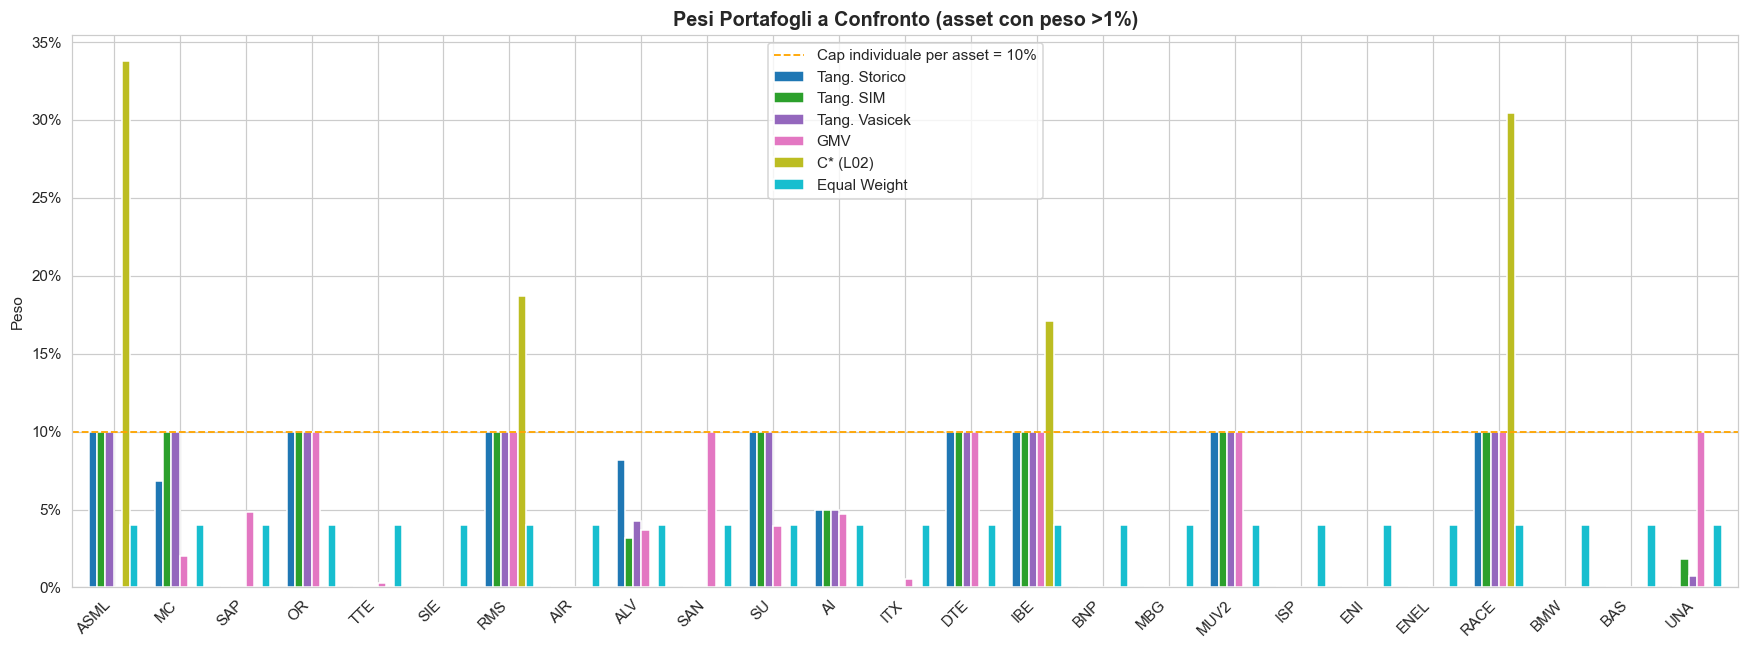

In [30]:
# Grafico pesi a confronto
pesi_df = pd.DataFrame({
    'Tang. Storico': res_tang_hist.x,
    'Tang. SIM'    : res_tang_sim.x,
    'Tang. Vasicek': res_tang_vas.x,
    'GMV'          : res_gmv.x,
    'C* (L02)'     : w_cstar,
    'Equal Weight' : np.array([1/n_assets]*n_assets)
}, index=[c.upper() for c in log_ret.columns])

pesi_plot = pesi_df[pesi_df.max(axis=1) > 0.01]

pesi_plot.plot(kind='bar', figsize=(16, 6), width=0.75,
               colormap='tab10', edgecolor='white')
# Linea di riferimento al cap settoriale (energy e automotive)
plt.axhline(W_MAX, color='orange', linestyle='--', linewidth=1.2,
            label=f'Cap individuale per asset = {W_MAX:.0%}')
plt.title('Pesi Portafogli a Confronto (asset con peso >1%)', fontsize=13, fontweight='bold')
plt.ylabel('Peso')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y,_: f'{y:.0%}'))
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()


### 2.15 – Analisi di Robustezza (1): avversione al rischio
Come cambia la composizione ottimale al variare del rendimento target (proxy dell'avversione al rischio).


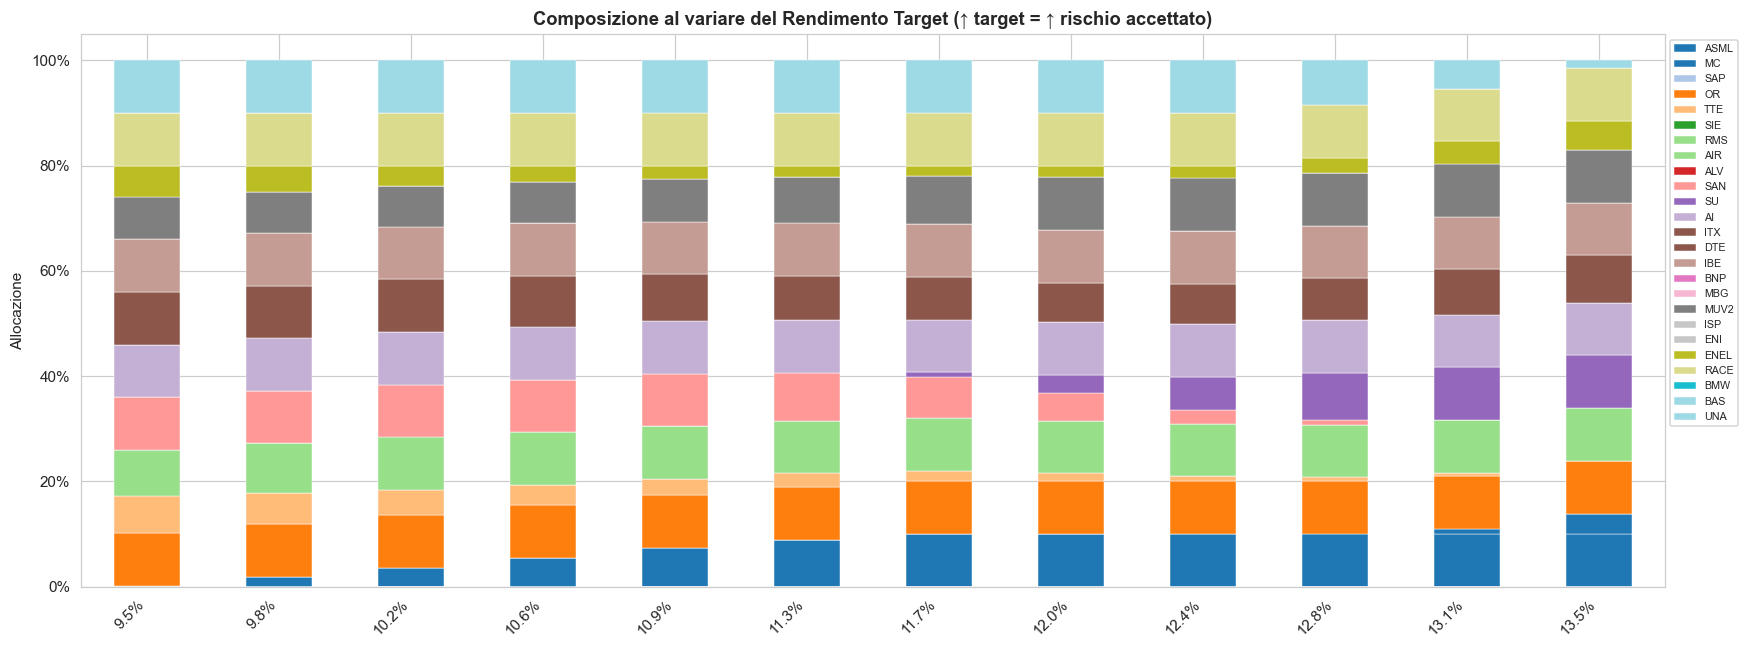

In [31]:
# Ricalcola il portafoglio ottimale per 12 valori di rendimento target equidistanti sul ramo efficiente
target_rets_rob = np.linspace(
    rets_sim[imin_s] * 1.05,
    rets_sim[min(imax_s-1, len(rets_sim)-1)] * 0.95,
    12
)
weights_rob, labels_rob = [], []

for tr in target_rets_rob:
    cons_rob = (
        {'type': 'eq', 'fun': lambda x: np.sum(x) - 1},
        {'type': 'eq', 'fun': lambda x, tr=tr: np.dot(x, mu_vec_sim) - tr}
    )
    res_r = sco.minimize(
        lambda w, c=cov_mat_sim: np.sqrt(np.dot(w.T, np.dot(c, w))),
        w0, method='SLSQP', bounds=bounds, constraints=cons_rob
    )
    if res_r.success:
        weights_rob.append(res_r.x)
        labels_rob.append(f'{tr:.1%}')

# Grafico stacked bar: la rotazione dei pesi mostra come cambia l'allocazione con il rischio accettato
pd.DataFrame(weights_rob,
             columns=[c.upper() for c in log_ret.columns],
             index=labels_rob
).plot(kind='bar', stacked=True, figsize=(16, 6), colormap='tab20',
       edgecolor='white', linewidth=0.3)
plt.title('Composizione al variare del Rendimento Target (↑ target = ↑ rischio accettato)',
          fontsize=12, fontweight='bold')
plt.ylabel('Allocazione')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y,_: f'{y:.0%}'))
plt.xticks(rotation=45, ha='right')
plt.legend(loc='upper left', bbox_to_anchor=(1,1), fontsize=7)
plt.tight_layout()
plt.show()


### 2.16 – Analisi di Robustezza (2): sensitività alle stime di mu
Come cambia il portafoglio di tangenza quando i rendimenti attesi vengono perturbati del ±10/20%.


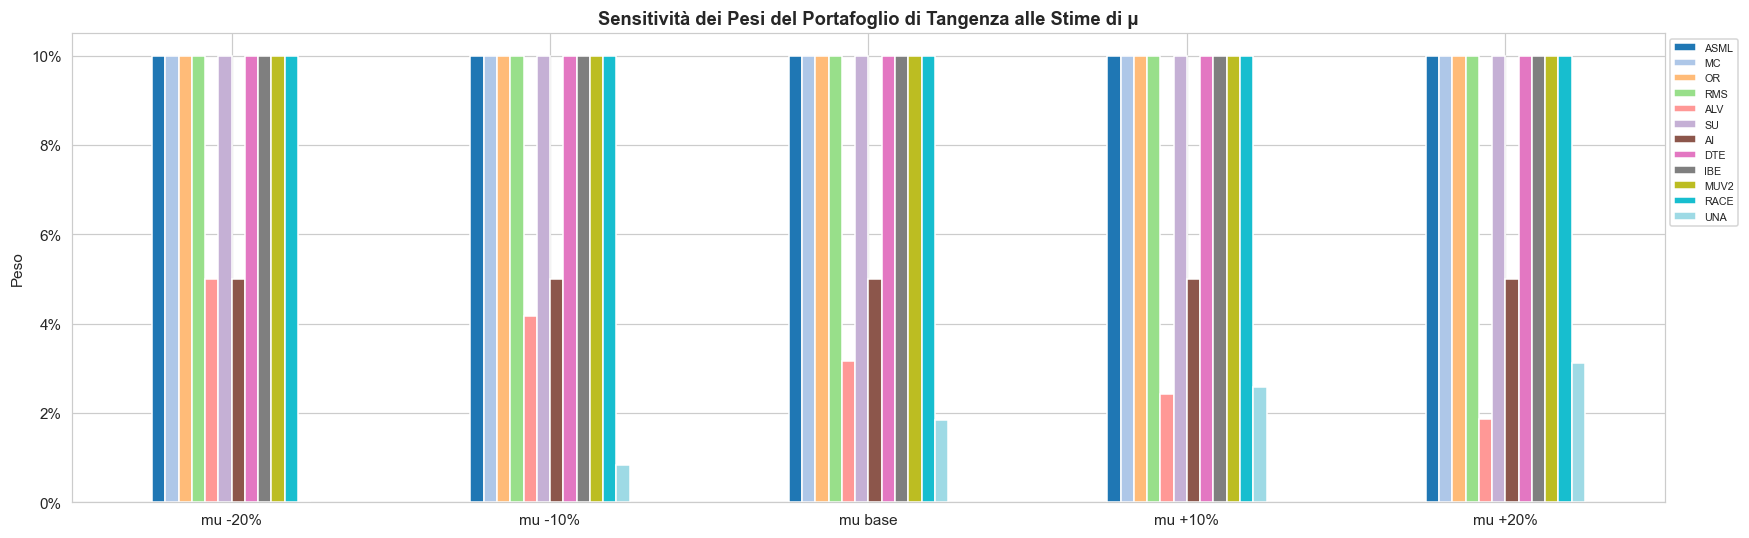


=== SHARPE AL VARIARE DI μ ===
  mu -20%: 0.5516
  mu -10%: 0.6465
  mu base: 0.7416
  mu +10%: 0.8369
  mu +20%: 0.9322


In [32]:
# Perturbazione del vettore mu: ±10% e ±20% rispetto alla stima base SIM
perturbazioni = {
    'mu -20%': mu_vec_sim * 0.80,
    'mu -10%': mu_vec_sim * 0.90,
    'mu base': mu_vec_sim,
    'mu +10%': mu_vec_sim * 1.10,
    'mu +20%': mu_vec_sim * 1.20,
}

# Per ogni scenario, ricalcola il portafoglio di tangenza e registra pesi e Sharpe
pesi_pert, sharpe_pert = {}, {}
for label, mu_p in perturbazioni.items():
    res_p = sco.minimize(
        neg_sharpe, w0,
        args=(mu_p, cov_mat_sim, rf_annuo),
        method='SLSQP', bounds=bounds, constraints=constraints
    )
    pesi_pert[label]   = res_p.x
    sharpe_pert[label] = -res_p.fun

df_pert = pd.DataFrame(pesi_pert, index=[c.upper() for c in log_ret.columns])
df_pert[df_pert.max(axis=1) > 0.01].T.plot(
    kind='bar', figsize=(16, 5), colormap='tab20', edgecolor='white')
plt.title('Sensitività dei Pesi del Portafoglio di Tangenza alle Stime di μ',
          fontsize=12, fontweight='bold')
plt.ylabel('Peso')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y,_: f'{y:.0%}'))
plt.xticks(rotation=0)
plt.legend(loc='upper left', bbox_to_anchor=(1,1), fontsize=7)
plt.tight_layout()
plt.show()

print('\n=== SHARPE AL VARIARE DI μ ===')
for l, sr in sharpe_pert.items():
    print(f'  {l}: {sr:.4f}')


### 2.17 – Portafoglio finale
Selezione e presentazione del portafoglio finale: VaR Monte Carlo vincolato con input SIM+Vasicek.


In [33]:
# Funzione di utilità: calcola rendimento, volatilità e Sharpe per qualsiasi portafoglio
def calcola_metriche(pesi, mu, cov, nome):
    rendimento = np.dot(pesi, np.asarray(mu))
    volatilita = np.sqrt(np.dot(pesi.T, np.dot(np.asarray(cov), pesi)))
    sharpe     = (rendimento - rf_annuo) / volatilita
    return {'Portafoglio': nome,
            'Rendimento Atteso': rendimento,
            'Volatilità': volatilita,
            'Indice di Sharpe': sharpe}

# Confronto finale tra 5 strategie con i rispettivi input di stima
lista_metriche = [
    calcola_metriche(np.array([1/n_assets]*n_assets), mu_sim.values,     cov_sim.values,     '1. Equal-Weight (1/N)'),
    calcola_metriche(res_gmv.x,                       mu_sim.values,     cov_sim.values,     '2. Minima Varianza (GMV)'),
    calcola_metriche(res_tang_vas.x,                  mu_sim_vas.values, cov_sim_vas.values, '3. Tangenza SIM+Vasicek'),
    calcola_metriche(w_kataoka,                       mu_sim_vas.values, cov_sim_vas.values, '4. Kataoka (α=5%)'),
    calcola_metriche(w_var_mc,                        mu_sim_vas.values, cov_sim_vas.values, '5. VaR MC (α=5%)'),
]

df_confronto = pd.DataFrame(lista_metriche).set_index('Portafoglio')
df_view = df_confronto.copy()
df_view['Rendimento Atteso'] = df_view['Rendimento Atteso'].map('{:.2%}'.format)
df_view['Volatilità']        = df_view['Volatilità'].map('{:.2%}'.format)
df_view['Indice di Sharpe']  = df_view['Indice di Sharpe'].map('{:.4f}'.format)
display(df_view)

# Portafoglio finale: VaR MC vincolato (input SIM+Vasicek, vincoli settoriali)
# Motivazione: unico criterio che non assume normalità, più robusto alle code fat (JB sez. 1.5)
w_finale    = w_var_mc
nome_finale = 'VaR Monte Carlo – vincolato (α=5%)'
mu_finale   = mu_sim_vas.values
cov_finale  = cov_sim_vas.values

ret_finale = np.dot(w_finale, mu_finale)
vol_finale = np.sqrt(np.dot(w_finale, np.dot(cov_finale, w_finale)))
sr_finale  = (ret_finale - rf_annuo) / vol_finale
var_mc_fin = np.percentile(ret_matrix @ w_finale, ALPHA_VAR * 100) * np.sqrt(FREQ)
pesi_finali = pd.Series(w_finale, index=log_ret.columns).sort_values(ascending=False)

print(f'=== PORTAFOGLIO FINALE: {nome_finale} ===')
print(f'Rendimento Atteso (ann.) : {ret_finale:.2%}')
print(f'Volatilità (ann.)         : {vol_finale:.2%}')
print(f'Sharpe Ratio             : {sr_finale:.4f}')
print(f'VaR MC al 95% (ann.)     : {var_mc_fin:.2%}')
print(f'HHI                      : {hhi(w_finale):.4f}')
print(f'N° asset attivi (>1%)     : {(w_finale > 0.01).sum()}')
print()
print('--- PESI OTTIMALI ---')
print(pesi_finali[pesi_finali > 0.001].apply(lambda x: f'{x:.2%}').to_string())


,Rendimento Atteso,Volatilità,Indice di Sharpe
Portafoglio,,,
1. Equal-Weight (1/N),8.55%,15.88%,0.3494
2. Minima Varianza (GMV),9.91%,12.31%,0.5611
3. Tangenza SIM+Vasicek,13.76%,14.61%,0.7364
4. Kataoka (α=5%),12.29%,13.26%,0.7005
5. VaR MC (α=5%),8.93%,13.91%,0.4264


=== PORTAFOGLIO FINALE: VaR Monte Carlo – vincolato (α=5%) ===
Rendimento Atteso (ann.) : 8.93%
Volatilità (ann.)         : 13.91%
Sharpe Ratio             : 0.4264
VaR MC al 95% (ann.)     : -13.38%
HHI                      : 0.0776
N° asset attivi (>1%)     : 15

--- PESI OTTIMALI ---
una     10.00%
muv2    10.00%
dte      9.63%
or       9.59%
ibe      9.06%
san      8.66%
race     7.89%
air      6.80%
rms      6.42%
mbg      6.02%
sie      4.53%
eni      3.31%
su       3.10%
tte      2.22%
isp      1.05%
sap      0.49%
alv      0.41%
enel     0.38%
bmw      0.29%
mc       0.10%


HHI: 0.0776
Peso nei primi 5 asset: 48.28%


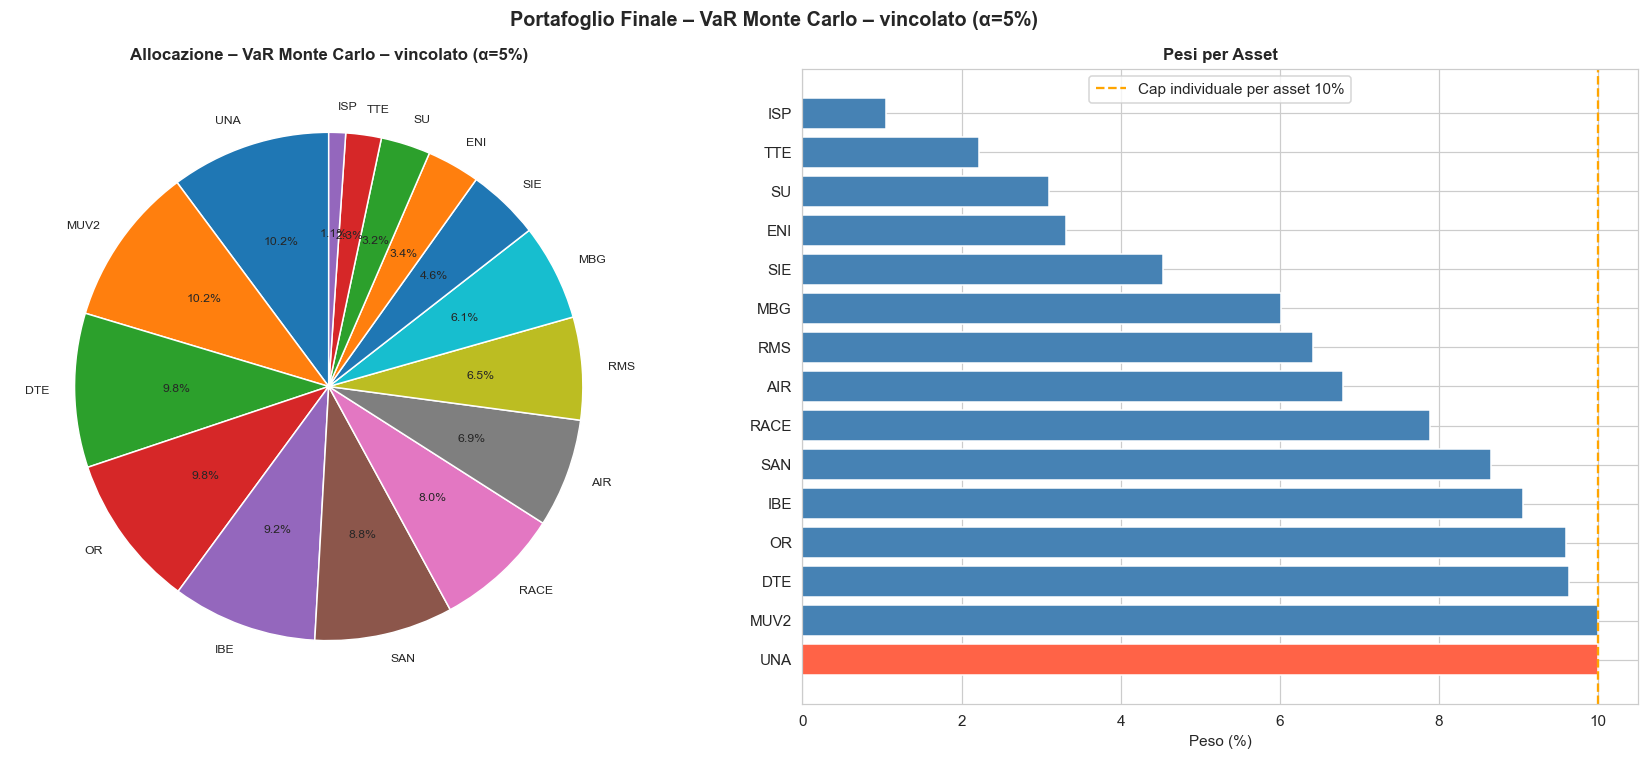

In [36]:
# Grafico a torta: allocazione percentuale del portafoglio finale
# Grafico a barre orizzontali: pesi ordinati con linea del cap individuale
pesi_plot_finale = pesi_finali[pesi_finali > 0.005]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].pie(pesi_plot_finale,
            labels=[c.upper() for c in pesi_plot_finale.index],
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 8})
axes[0].set_title(f'Allocazione – {nome_finale}', fontsize=11, fontweight='bold')

colors = ['tomato' if w == w_finale.max() else 'steelblue' for w in pesi_plot_finale]
axes[1].barh([c.upper() for c in pesi_plot_finale.index],
             pesi_plot_finale*100, color=colors, edgecolor='white')
axes[1].axvline(W_MAX * 100, color='orange', linestyle='--',
                linewidth=1.5, label=f'Cap individuale per asset {W_MAX:.0%}')
axes[1].set_xlabel('Peso (%)')
axes[1].set_title('Pesi per Asset', fontsize=11, fontweight='bold')
axes[1].legend()

plt.suptitle(f'Portafoglio Finale – {nome_finale}', fontsize=13, fontweight='bold')
plt.tight_layout()

# Indice HHI e concentrazione nei primi 5 asset
def hhi(weights):
    weights = np.array(weights)
    return np.sum(weights**2)

hhi_value = hhi(pesi_finali)
print(f"HHI: {hhi_value:.4f}")

def effective_n(weights):
    # N efficace: 1/HHI -> misura il numero di asset "equivalenti" in un portafoglio diversificato
    return 1 / np.sum(np.array(weights)**2)

weights_series   = pd.Series(pesi_finali)
top_weights      = weights_series.sort_values(ascending=False).head(10)
top5_concentration = top_weights.head(5).sum()
print(f"Peso nei primi 5 asset: {top5_concentration:.2%}")

plt.show()


### Sezione 3 – Backtest interattivo
Interfaccia grafica in una finestra separata per simulare l'andamento storico del portafoglio finale vs benchmark SX5E.


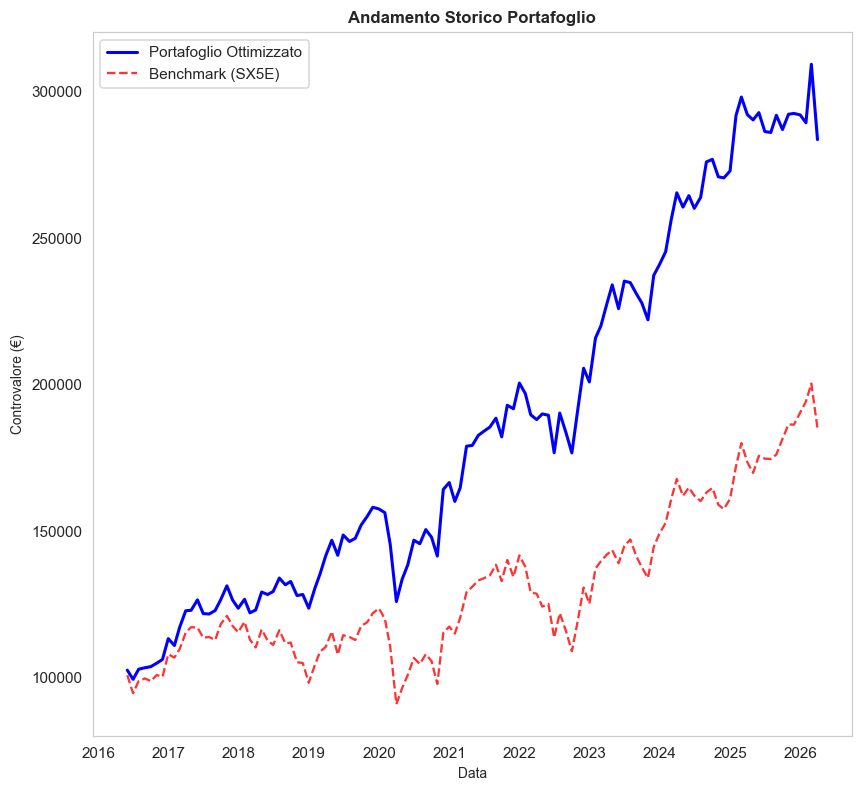

In [35]:
# Applicazione Tkinter per il backtest interattivo del portafoglio finale
# Permette di modificare pesi, periodo e capitale iniziale e visualizzare l'andamento vs benchmark
import tkinter as tk
from tkinter import messagebox
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg

class BacktesterAppIntegrato:
    def __init__(self, master, df_prezzi, pesi_input, asset_cols):
        self.master = master
        self.master.title("Analisi Backtesting Portafoglio")
        self.master.geometry("1250x900")
        self.df_prezzi = df_prezzi.copy()
        self.asset_cols = asset_cols
        if isinstance(pesi_input, pd.Series):
            self.pesi_iniziali = pesi_input.to_dict()
        else:
            self.pesi_iniziali = pesi_input
        self.setup_ui()

    def setup_ui(self):
        main_frame = tk.Frame(self.master)
        main_frame.pack(fill=tk.BOTH, expand=True, padx=15, pady=15)

        # Pannello sinistro: parametri e pesi
        left_frame = tk.Frame(main_frame)
        left_frame.pack(side=tk.LEFT, fill=tk.Y, padx=(0, 20))

        tk.Label(left_frame, text="Parametri Portafoglio", font=("Arial", 10, "bold")).pack(anchor="w", pady=(0, 5))

        params_frame = tk.Frame(left_frame)
        params_frame.pack(fill=tk.X, pady=5)

        tk.Label(params_frame, text="Capitale Iniziale (€):", font=("Arial", 9)).grid(row=0, column=0, sticky="w", pady=2)
        self.capitale_entry = tk.Entry(params_frame, width=15, font=("Arial", 9))
        self.capitale_entry.insert(0, "100000")
        self.capitale_entry.grid(row=0, column=1, sticky="w", padx=5)

        tk.Label(params_frame, text="Data Inizio (YYYY-MM-DD):", font=("Arial", 9)).grid(row=1, column=0, sticky="w", pady=2)
        self.start_date_entry = tk.Entry(params_frame, width=15, font=("Arial", 9))
        self.start_date_entry.insert(0, str(self.df_prezzi.index.min().date()))
        self.start_date_entry.grid(row=1, column=1, sticky="w", padx=5)

        tk.Label(params_frame, text="Data Fine (YYYY-MM-DD):", font=("Arial", 9)).grid(row=2, column=0, sticky="w", pady=2)
        self.end_date_entry = tk.Entry(params_frame, width=15, font=("Arial", 9))
        self.end_date_entry.insert(0, str(self.df_prezzi.index.max().date()))
        self.end_date_entry.grid(row=2, column=1, sticky="w", padx=5)

        # Griglia di input pesi per asset
        tk.Label(left_frame, text="Allocazione Asset (%)", font=("Arial", 10, "bold")).pack(anchor="w", pady=(15, 5))
        self.assets_grid_frame = tk.Frame(left_frame, relief=tk.SUNKEN, borderwidth=1, padx=5, pady=5)
        self.assets_grid_frame.pack(fill=tk.X, expand=False)

        self.weight_entries = {}
        for i, asset in enumerate(self.asset_cols):
            row = i % 13
            col_base = (i // 13) * 2
            lbl = tk.Label(self.assets_grid_frame, text=asset.upper(), font=("Arial", 9, "bold"), width=10, anchor="w")
            lbl.grid(row=row, column=col_base, padx=(5, 1), pady=3, sticky="w")
            ent = tk.Entry(self.assets_grid_frame, width=7, font=("Arial", 9))
            valore_peso = self.pesi_iniziali.get(asset, 0.0) * 100
            ent.insert(0, f"{valore_peso:.2f}")
            ent.grid(row=row, column=col_base+1, padx=(1, 15), pady=3)
            self.weight_entries[asset] = ent

        # Pulsante di avvio backtest
        self.btn_run = tk.Button(left_frame, text="Esegui Backtest", command=self.run_analysis,
                                 height=2, font=("Arial", 10, "bold"), bg="steelblue", fg="white")
        self.btn_run.pack(fill=tk.X, pady=(25, 15))

        # Pannello risultati: rendimento totale, volatilità, Sharpe
        self.metrics_frame = tk.LabelFrame(left_frame, text="Risultati Analisi", font=("Arial", 9, "bold"), pady=10)
        self.metrics_frame.pack(fill=tk.X)
        self.metric_labels = {}
        for m in ["Rendimento Totale", "Volatilità Ann.", "Sharpe Ratio"]:
            f = tk.Frame(self.metrics_frame)
            f.pack(fill=tk.X, padx=10, pady=3)
            tk.Label(f, text=f"{m}:", font=("Arial", 9)).pack(side=tk.LEFT)
            lbl = tk.Label(f, text="-", font=("Arial", 9, "bold"))
            lbl.pack(side=tk.RIGHT)
            self.metric_labels[m] = lbl

        # Pannello destro: grafico matplotlib integrato in Tkinter
        right_frame = tk.Frame(main_frame, relief=tk.GROOVE, borderwidth=1)
        right_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)
        self.fig, self.ax = plt.subplots(figsize=(7, 7))
        self.ax.set_axis_off()
        self.canvas_plot = FigureCanvasTkAgg(self.fig, master=right_frame)
        self.canvas_plot.get_tk_widget().pack(fill=tk.BOTH, expand=True, padx=5, pady=5)

    def run_analysis(self):
        try:
            capitale = float(self.capitale_entry.get())
            start_d  = self.start_date_entry.get()
            end_d    = self.end_date_entry.get()

            # Lettura pesi dall'interfaccia e normalizzazione se la somma si discosta da 1
            pesi = np.array([float(self.weight_entries[a].get()) / 100 for a in self.asset_cols])
            if abs(pesi.sum() - 1.0) > 0.05:
                pesi = pesi / pesi.sum()

            # Calcolo rendimenti percentuali e curva cumulata del portafoglio
            df_slice  = self.df_prezzi.loc[start_d:end_d].copy()
            returns   = df_slice[self.asset_cols].pct_change().dropna()
            port_returns = returns.dot(pesi)
            cum_port  = (1 + port_returns).cumprod() * capitale

            # Benchmark: curva cumulata dell'EuroStoxx 50
            bench_returns = df_slice['sx5e_price'].pct_change().dropna()
            cum_bench = (1 + bench_returns).cumprod() * capitale

            self.ax.clear()
            self.ax.set_axis_on()
            self.ax.plot(cum_port.index, cum_port.values,
                         label="Portafoglio Ottimizzato", color="blue", linewidth=2)
            self.ax.plot(cum_bench.index, cum_bench.values,
                         label="Benchmark (SX5E)", color="red", linestyle="--", alpha=0.8)
            self.ax.set_title("Andamento Storico Portafoglio", fontsize=11, fontweight='bold')
            self.ax.set_xlabel("Data", fontsize=9)
            self.ax.set_ylabel("Controvalore (€)", fontsize=9)
            self.ax.legend(loc='best')
            self.ax.grid(False)
            self.fig.tight_layout()
            self.canvas_plot.draw()

            # Metriche di performance: rendimento totale, volatilità annualizzata, Sharpe
            tr     = (cum_port.iloc[-1] / capitale) - 1
            vol    = port_returns.std() * np.sqrt(12)
            sharpe = (tr / vol) if vol != 0 else 0
            self.metric_labels["Rendimento Totale"].config(text=f"{tr*100:.2f}%")
            self.metric_labels["Volatilità Ann."].config(text=f"{vol*100:.2f}%")
            self.metric_labels["Sharpe Ratio"].config(text=f"{sharpe:.2f}")

        except Exception as e:
            messagebox.showerror("Errore", f"Errore nel calcolo: {e}")

if __name__ == "__main__":
    # Chiude l'eventuale finestra precedente prima di aprirne una nuova
    vecchia_root = globals().get('root')
    if vecchia_root:
        try: vecchia_root.destroy()
        except: pass
    root = tk.Tk()
    app  = BacktesterAppIntegrato(root, df_raw, pesi_finali, ASSET_COLS)
    root.mainloop()
